# Buscador inteligente Ferreplast – Machine Learning
Proyecto: búsqueda de productos con TF-IDF + CNN de categorías
Integrantes: ...


## 1. Import y conexion con drive

In [1]:
# ============================================================
# PASO 1.1 - CONECTAR GOOGLE DRIVE Y CREAR CARPETAS
# ============================================================
# Colab borra todos los archivos cuando se reinicia la sesión.
# Por eso guardamos todo en Google Drive, donde queda permanente.
#
# La carpeta del proyecto está compartida. Para que Colab la vea,
# cada integrante debe crear un acceso directo en "Mi unidad".

from google.colab import drive   # módulo de Colab para acceder a Drive
drive.mount('/content/drive')    # pide permiso y conecta tu Drive

import os                        # librería para manejar carpetas y archivos

# Rutas posibles donde puede estar la carpeta del proyecto,
# según de qué carpeta se haya creado el acceso directo:
#   1) acceso directo de "busqueda inteligente"
#   2) acceso directo de "Pagina Ferreplast"
RUTAS_POSIBLES = [
    '/content/drive/MyDrive/busqueda inteligente',
    '/content/drive/MyDrive/Pagina Ferreplast/machine learning/busqueda inteligente',
]

# Buscamos la primera ruta que exista
BASE = None
for ruta in RUTAS_POSIBLES:
    if os.path.exists(ruta):
        BASE = ruta
        break

# Si no se encontró ninguna, mostramos qué hay en "Mi unidad"
# para ayudar a encontrar el nombre correcto
if BASE is None:
    print('No se encontró la carpeta del proyecto.')
    print('Contenido de Mi unidad:')
    print(os.listdir('/content/drive/MyDrive'))
    raise FileNotFoundError('Crea el acceso directo en "Mi unidad" y vuelve a correr esta celda.')

# Subcarpetas para mantener el proyecto ordenado:
#   datos   -> catálogo de productos y búsquedas de prueba
#   modelos -> modelos entrenados (TF-IDF y CNN)
#   export  -> archivos finales que se suben a la página
CARPETAS = ['datos', 'modelos', 'export']

for c in CARPETAS:
    # exist_ok=True evita error si la carpeta ya existe
    os.makedirs(f'{BASE}/{c}', exist_ok=True)

# Mostramos la estructura creada para confirmar
print('Carpeta del proyecto:', BASE)
for c in CARPETAS:
    print('  ├──', c)

Mounted at /content/drive
Carpeta del proyecto: /content/drive/MyDrive/busqueda inteligente
  ├── datos
  ├── modelos
  ├── export


In [2]:
# ============================================================
# PASO 1.2 - IMPORTAR LIBRERÍAS
# ============================================================
# Colab ya trae todas estas librerías instaladas.

import pandas as pd          # manejo de tablas (leer/guardar CSV)
import numpy as np           # cálculos numéricos con vectores y matrices
import sklearn               # machine learning clásico (TF-IDF, métricas)
import tensorflow as tf      # deep learning (para la CNN más adelante)
import json                  # guardar el modelo en formato JSON para la web
import random                # generar datos aleatorios (errores de tipeo)
import unicodedata           # quitar tildes del texto
import re                    # expresiones regulares para limpiar texto

# Mostramos las versiones: sirve para documentarlas en el informe
# y para que todo el grupo trabaje con las mismas
print('pandas      ', pd.__version__)
print('numpy       ', np.__version__)
print('scikit-learn', sklearn.__version__)
print('tensorflow  ', tf.__version__)

pandas       2.2.3
numpy        2.4.6
scikit-learn 1.6.1
tensorflow   2.21.0


In [3]:
# ============================================================
# PASO 1.3 - CONFIGURACIÓN GLOBAL
# ============================================================

# SEMILLA ALEATORIA
# Los modelos usan números aleatorios (al mezclar datos, al iniciar
# los pesos de la red, etc.). Fijar la semilla hace que cada vez que
# se corra el notebook salgan EXACTAMENTE los mismos resultados.
SEED = 42
random.seed(SEED)         # semilla para la librería random de Python
np.random.seed(SEED)      # semilla para numpy
tf.random.set_seed(SEED)  # semilla para tensorflow

# RUTAS DEL PROYECTO
# Se definen una sola vez y se usan en todo el notebook.
RUTA_DATOS   = f'{BASE}/datos'
RUTA_MODELOS = f'{BASE}/modelos'
RUTA_EXPORT  = f'{BASE}/export'

print('Configuración lista')
print('Datos   ->', RUTA_DATOS)
print('Modelos ->', RUTA_MODELOS)
print('Export  ->', RUTA_EXPORT)

Configuración lista
Datos   -> /content/drive/MyDrive/busqueda inteligente/datos
Modelos -> /content/drive/MyDrive/busqueda inteligente/modelos
Export  -> /content/drive/MyDrive/busqueda inteligente/export


## Paso 2 – Datos reales: Shopping Queries Dataset (ESCI)
Dataset público de Amazon (Reddy et al., 2022) con búsquedas reales de clientes
y productos etiquetados por personas: E = Exacto, S = Sustituto,
C = Complemento, I = Irrelevante.
Usamos solo la parte en español, filtrada a productos de ferretería.
Fuente: https://github.com/amazon-science/esci-data

In [4]:
# ============================================================
# PASO 2.1 - DESCARGAR ESCI
# ============================================================
# Son 2 archivos .parquet (tablas comprimidas):
#   - examples: búsqueda + producto + etiqueta de relevancia (E/S/C/I)
#   - products: datos del producto (título, descripción, marca)
# Se bajan al disco temporal de Colab, NO a Drive, porque son grandes.
# En Drive guardaremos solo la parte filtrada.

RUTA_ESCI = '/content/esci'
os.makedirs(RUTA_ESCI, exist_ok=True)

URL_BASE = 'https://github.com/amazon-science/esci-data/raw/main/shopping_queries_dataset'
ARCHIVOS = ['shopping_queries_dataset_examples.parquet',
            'shopping_queries_dataset_products.parquet']

for archivo in ARCHIVOS:
    destino = f'{RUTA_ESCI}/{archivo}'
    if not os.path.exists(destino):                       # solo descarga si no existe
        print('Descargando:', archivo)
        !wget -q -O "{destino}" "{URL_BASE}/{archivo}"     # -q silencioso, -O destino

    mb = os.path.getsize(destino) / 1024**2               # tamaño en MB
    print(f'{archivo}: {mb:.1f} MB')

    # Si pesa casi nada, la descarga falló (GitHub entregó un archivo vacío)
    if mb < 1:
        print('  ⚠ Descarga incompleta: borra el archivo y vuelve a correr la celda')

Descargando: shopping_queries_dataset_examples.parquet
shopping_queries_dataset_examples.parquet: 48.9 MB
Descargando: shopping_queries_dataset_products.parquet
shopping_queries_dataset_products.parquet: 1057.5 MB


In [5]:
# ============================================================
# PASO 2.2 - CARGAR DATOS EN ESPAÑOL E INGLÉS
# ============================================================
# 'es' = Amazon España, 'us' = Amazon Estados Unidos (inglés).
# ESCI no incluye alemán; sus idiomas son es, us y jp.

IDIOMAS = ['es', 'us']

df_examples = pd.read_parquet(
    f'{RUTA_ESCI}/shopping_queries_dataset_examples.parquet',
    filters=[('product_locale', 'in', IDIOMAS)],
)

df_products = pd.read_parquet(
    f'{RUTA_ESCI}/shopping_queries_dataset_products.parquet',
    columns=['product_id', 'product_title', 'product_description',
             'product_bullet_point', 'product_brand', 'product_locale'],
    filters=[('product_locale', 'in', IDIOMAS)],
)

# Resumen por idioma
print('Búsquedas únicas por idioma:')
print(df_examples.groupby('product_locale')['query'].nunique())
print('\nProductos por idioma:')
print(df_products['product_locale'].value_counts())

Búsquedas únicas por idioma:
product_locale
es    15180
us    97345
Name: query, dtype: int64

Productos por idioma:
product_locale
us    1215854
es     260011
Name: count, dtype: int64


In [6]:
# ============================================================
# PASO 2.3 - FILTRAR BÚSQUEDAS DE FERRETERÍA (ES + EN)  [v3]
# ============================================================
# Cambios respecto a la v2:
#   - Se ignora "sin X" / "without X" / "no drill": "barra ducha sin taladro"
#     NO busca un taladro, busca algo que se instala sin taladro.
#   - Palabras ambiguas reemplazadas por frases específicas:
#       "taco" -> "taco nylon" (evita "tacón"), "nut" -> "hex nut" (evita "nutcracker"),
#       "nail" -> "finishing nails" (evita uñas de manicure)
#   - Más exclusiones: calzado, manicure, puzzles, juguetes de niños.

PALABRAS = {
    'es': ['taladro', 'atornillador', 'destornillador', 'martillo', 'alicate',
           'llave inglesa', 'llave allen', 'tornillo', 'tuerca', 'arandela',
           'clavo', 'taco nylon', 'tacos de pared', 'taco fischer', 'broca',
           'sierra circular', 'sierra de calar', 'sierra de mano', 'serrucho',
           'radial', 'amoladora', 'lijadora', 'lija', 'ingletadora', 'caladora',
           'nivel laser', 'flexometro', 'cinta metrica', 'multimetro', 'soldador',
           'silicona selladora', 'silicona sanitaria', 'pistola de silicona',
           'masilla', 'pegamento madera', 'pegamento contacto', 'brocha',
           'pintura pared', 'pintura exterior', 'barniz', 'disolvente', 'grifo',
           'tuberia', 'teflon', 'sifon', 'manguera', 'enchufe', 'interruptor',
           'regleta', 'bombilla', 'cable electrico', 'guantes de trabajo',
           'gafas de proteccion', 'casco de obra', 'casco de seguridad',
           'caja de herramientas', 'herramienta', 'escalera', 'carretilla',
           'pala', 'rastrillo', 'tijera de podar', 'cemento', 'mortero', 'yeso'],
    'us': ['drill', 'screwdriver', 'hammer', 'pliers', 'wrench', 'allen key',
           'screw', 'bolt', 'hex nut', 'lock nut', 'wing nut', 'lug nut',
           'washer', 'finishing nails', 'framing nails', 'brad nails', 'nail gun',
           'drywall anchor', 'drill bit', 'circular saw', 'miter saw', 'hand saw',
           'saw blade', 'reciprocating saw', 'oscillating saw', 'jigsaw blade',
           'angle grinder', 'sander', 'sandpaper', 'laser level', 'tape measure',
           'multimeter', 'soldering iron', 'caulk', 'silicone sealant', 'putty',
           'wood glue', 'epoxy', 'wall paint', 'spray paint', 'varnish', 'faucet',
           'pvc pipe', 'copper pipe', 'pipe wrench', 'teflon tape', 'garden hose',
           'outlet', 'light switch', 'power strip', 'light bulb', 'electrical wire',
           'work gloves', 'safety glasses', 'hard hat', 'toolbox', 'tool set',
           'tool bag', 'ladder', 'wheelbarrow', 'shovel', 'rake',
           'pruning shears', 'cement', 'mortar', 'drywall'],
}

EXCLUIR = {
    'es': ['usb', 'hdmi', 'iphone', 'samsung', 'movil', 'juguete', 'muñeca',
           'pelo', 'peluca', 'unas', 'maquillaje', 'lego', 'billar', 'gaming',
           'auricular', 'bebe', 'airpods', 'carcasa', 'funda', 'mascota',
           'perro', 'gato', 'cocina', 'cortina', 'visillo', 'bicicleta', 'moto',
           'tacon', 'bota', 'zapato', 'zapatilla', 'mujer', 'niño', 'niña',
           'pulsera', 'lampara', 'microondas', 'coche''padel', 'acuario', 'zapatero'],
    'us': ['usb', 'hdmi', 'iphone', 'samsung', 'phone', 'toy', 'doll', 'hair',
           'wig', 'lash', 'nail polish', 'nail art', 'press on', 'acrylic',
           'manicure', 'makeup', 'lego', 'kids', 'costume', 'gaming', 'headphone',
           'airpods', 'case', 'baby', 'pet', 'dog', 'cat', 'skate', 'ramp',
           'smoking', 'tobacco', 'kitchen', 'puzzle', 'cracker', 'christmas',
           'bike', 'motorcycle', 'guitar', 'hard drive''chocolate', 'agility', 'clothes'],
}
# ============================================================
# RESINA - LÍNEA PRINCIPAL DE VENTA DE FERREPLAST (versión ampliada)
# ============================================================
# Se incluyen todos los INSUMOS para trabajar con resina, agrupados por tipo.
# Se excluyen OBJETOS hechos de resina (figuras, muebles) y usos que no
# corresponden (uñas, odontología, repostería, incienso).
#
# Nota: el filtro busca por prefijo, por eso se usan frases específicas
# ("glitter for resin" en vez de "glitter", que traería maquillaje).

RESINA_ES = [
    # --- Tipos de resina ---
    'resina epoxi', 'resina epoxica', 'resina epoxy', 'epoxi', 'epoxica',
    'resina de poliester', 'resina poliester', 'resina de poliuretano',
    'resina poliuretano', 'resina acrilica', 'resina uv', 'resina ultravioleta',
    'resina de colada', 'resina para colada', 'resina de laminacion',
    'resina cristal', 'resina transparente', 'resina liquida', 'resina para',
    'resina artistica', 'resina de joyeria', 'resina bicomponente',
    'resina 2 componentes', 'kit resina', 'kit de resina', 'resina viniléster',
    'resina vinilester', 'mesa de rio', 'mesa rio',
    # --- Catalizadores, endurecedores y aditivos ---
    'endurecedor', 'catalizador', 'mekp', 'peroxido', 'acelerante',
    'acelerador cobalto', 'cobalto', 'estireno', 'monomero', 'gelcoat',
    'topcoat', 'parafina', 'aerosil', 'silice pirogenica', 'microesferas',
    'carga mineral', 'talco industrial',
    # --- Refuerzos: fibra de vidrio y otras ---
    'fibra de vidrio', 'mat de fibra', 'manta de fibra', 'roving',
    'tejido de fibra', 'tela de fibra', 'velo de superficie', 'fibra de carbono',
    'tejido de carbono', 'kevlar',
    # --- Moldes y desmoldantes ---
    'molde de resina', 'moldes de resina', 'molde para resina', 'moldes para resina',
    'molde de silicona', 'moldes de silicona', 'silicona para moldes',
    'caucho de silicona', 'silicona rtv', 'silicona liquida para moldes',
    'desmoldante', 'cera desmoldante', 'alcohol polivinilico',
    'molde esfera', 'molde posavasos', 'molde bandeja', 'molde geoda', 'molde letras',
    # --- Color y decoración ---
    'pigmento resina', 'pigmentos resina', 'pigmento para resina',
    'pigmentos para resina', 'pigmento epoxi', 'pasta de color', 'colorante resina',
    'tinte resina', 'tinte alcohol', 'tintas al alcohol', 'mica en polvo',
    'polvo de mica', 'purpurina para resina', 'glitter resina', 'pan de oro',
    'hoja de oro', 'escamas metalicas',
    # --- Herramientas y equipos ---
    'vaso medidor', 'vasos medidores', 'vasos graduados', 'paletas mezcladoras',
    'palitos mezcladores', 'mezclador resina', 'soplete', 'pistola de calor',
    'olla a presion resina', 'camara de vacio', 'desgasificador', 'lampara uv',
    'balanza digital', 'rodillo desaireador', 'rodillo de laminar',
    # --- Seguridad ---
    'guantes de nitrilo', 'mascarilla vapores', 'mascara de gases',
    'respirador', 'filtro vapores organicos',
    # --- Masillas, acabados y pulido ---
    'masilla poliester', 'masilla automotriz', 'masilla epoxi', 'masilla de fibra',
    'pulimento', 'pasta de pulir', 'lija al agua', 'barniz epoxi', 'barniz epoxico',
    # --- Pisos y revestimientos ---
    'piso epoxico', 'suelo epoxi', 'pintura epoxi', 'autonivelante', 'impermeabilizante',
]

RESINA_US = [
    # --- Resin types ---
    'epoxy', 'epoxy resin', 'deep pour', 'table top epoxy', 'tabletop epoxy',
    'river table', 'casting resin', 'uv resin', 'art resin', 'doming resin',
    'crystal clear resin', 'clear resin', 'polyester resin', 'vinyl ester',
    'polyurethane resin', 'urethane resin', 'urethane casting', 'laminating resin',
    'finishing resin', 'coating resin', 'resin kit', 'resin starter kit',
    'two part epoxy', '2 part epoxy', 'resin for', 'for resin', 'for epoxy',
    # --- Hardeners, catalysts, additives ---
    'hardener', 'resin hardener', 'epoxy hardener', 'mekp', 'catalyst',
    'cobalt accelerator', 'styrene', 'gelcoat', 'gel coat', 'surfacing agent',
    'fumed silica', 'cabosil', 'microballoons', 'thickener for epoxy',
    # --- Reinforcements ---
    'fiberglass cloth', 'fiberglass mat', 'chopped strand', 'fiberglass roving',
    'fiberglass fabric', 'fiberglass repair', 'fiberglass kit', 'carbon fiber cloth',
    'carbon fiber fabric', 'kevlar fabric',
    # --- Molds and release agents ---
    'resin mold', 'resin molds', 'mold for resin', 'molds for resin',
    'silicone mold for resin', 'silicone rubber', 'mold making', 'mold rubber',
    'mold putty', 'mold release', 'release agent', 'release wax', 'pva release',
    'coaster mold', 'tray mold', 'sphere mold', 'geode mold', 'letter mold',
    'jewelry mold', 'pendant mold', 'river table mold',
    # --- Color and decoration ---
    'mica powder', 'pigment powder', 'resin pigment', 'epoxy pigment',
    'resin dye', 'resin colorant', 'alcohol ink', 'pigment paste',
    'glitter for resin', 'resin glitter', 'metallic flakes', 'gold leaf',
    'gold foil flakes', 'dried flowers for resin',
    # --- Tools and equipment ---
    'measuring cups', 'mixing cups', 'mixing sticks', 'stir sticks',
    'resin mixer', 'epoxy mixer', 'torch for resin', 'resin torch',
    'heat gun', 'pressure pot', 'vacuum chamber', 'degassing chamber',
    'uv lamp', 'uv light for resin', 'curing light', 'digital scale',
    'laminating roller', 'fiberglass roller', 'bubble roller',
    # --- Safety ---
    'nitrile gloves', 'respirator', 'organic vapor', 'vapor cartridge',
    # --- Fillers, finishing and polishing ---
    'body filler', 'bondo', 'epoxy putty', 'epoxy filler', 'marine epoxy',
    'polishing compound', 'wet sandpaper', 'epoxy primer',
    # --- Floors and coatings ---
    'epoxy floor', 'garage floor epoxy', 'floor coating', 'self leveling epoxy',
    'concrete sealer', 'epoxy paint', 'countertop epoxy',
]

# Exclusiones específicas de resina:
# objetos HECHOS de resina, uñas, odontología, repostería, incienso, velas, jabón
EXCLUIR_RESINA_ES = [
    'figura', 'figuras', 'estatua', 'mueble', 'armario', 'baul', 'silla',
    'tumbona', 'macetero', 'maceta', 'navidad', 'disney', 'tintin', 'belen',
    'manicura', 'pedicura', 'gel uv unas', 'dental', 'diente', 'reposteria',
    'horno', 'bizcocho', 'tarta', 'hielo', 'jabon', 'vela', 'incienso', 'copal',
]

EXCLUIR_RESINA_US = [
    'figurine', 'statue', 'furniture', 'wicker', 'chair', 'planter',
    'garden decor', 'frankincense', 'incense', 'copal', 'myrrh', 'nail art',
    'gel nail', 'nail hardener', 'nail polish', 'dental', 'tooth', 'teeth',
    'baking', 'cake', 'cupcake', 'ice cube', 'soap', 'candle', 'fondant',
    'medical gloves', 'exam gloves', 'food',
]

# Se agregan a las listas generales del filtro
PALABRAS['es'] += RESINA_ES
PALABRAS['us'] += RESINA_US
EXCLUIR['es']  += EXCLUIR_RESINA_ES
EXCLUIR['us']  += EXCLUIR_RESINA_US

print(f'Palabras clave ES: {len(PALABRAS["es"])}  (resina: {len(RESINA_ES)})')
print(f'Palabras clave US: {len(PALABRAS["us"])}  (resina: {len(RESINA_US)})')

def quitar_tildes(texto):
    """'Teflón' -> 'teflon'. Pasa a minúsculas y elimina tildes."""
    texto = unicodedata.normalize('NFD', str(texto).lower())
    return ''.join(c for c in texto if unicodedata.category(c) != 'Mn')

def quitar_negaciones(texto):
    """
    Borra la palabra que sigue a "sin" / "without" / "no":
      'barra ducha sin taladro' -> 'barra ducha'
    Así no se confunde "algo SIN taladro" con "buscar un taladro".
    """
    return re.sub(r'\b(?:sin|without|no)\s+\w+', ' ', texto)

busquedas_ferreteria = {}   # idioma -> conjunto de búsquedas filtradas

for idioma in IDIOMAS:
    # (?:...) = grupo sin captura; \b = inicio de palabra (acepta plurales)
    patron_in = re.compile(r'\b(?:' + '|'.join(map(re.escape, PALABRAS[idioma])) + ')')
    patron_ex = re.compile(r'\b(?:' + '|'.join(map(re.escape, EXCLUIR[idioma])) + ')')

    qs = pd.Series(df_examples.loc[df_examples['product_locale'] == idioma, 'query'].unique())
    qs_norm = qs.apply(quitar_tildes)
    qs_sin_neg = qs_norm.apply(quitar_negaciones)   # versión sin "sin X" para buscar palabras clave

    # Incluir: tiene palabra de ferretería (ignorando lo que va después de "sin")
    # Excluir: tiene alguna palabra prohibida en la búsqueda completa
    mask = qs_sin_neg.str.contains(patron_in) & ~qs_norm.str.contains(patron_ex)
    busquedas_ferreteria[idioma] = set(qs[mask])

    print(f'\n[{idioma}] búsquedas de ferretería: {mask.sum()}')
    for q in random.sample(sorted(busquedas_ferreteria[idioma]), 20):
        print('    -', q)

Palabras clave ES: 190  (resina: 125)
Palabras clave US: 190  (resina: 124)

[es] búsquedas de ferretería: 238
    - moldes de silicona para joyas
    - aplique extensible interruptor
    - 2 enchufes y 1 interruptor pared sin empotrar
    - real-techniques brochas
    - cinta teflon
    - brocas
    - bombillas philips
    - barniz dos componentes brillante
    - pulimento sin silicona
    - alicates crimpar
    - palanca para coche
    - tinte alcohol resina epoxi
    - kapsa enchufe
    - agua potable grifo
    - llave allen 8
    - escalera telescópica
    - 20 bombillas sin enchufe para espejo
    - 2 interruptor wifi sin neutro
    - alargue manguera grifo
    - bombillas led 2w

[us] búsquedas de ferretería: 969
    - coping saw blades 6 1/2 inch fine
    - light bulb changer for high ceilings with pole
    - oem parts washer
    - 10 w light bulbs
    - milwaukee m18 caulking gun
    - caulk remover
    - ryobi miter saw stand
    - power strip desk
    - respiratory mask
    -

In [7]:
# ============================================================
# PASO 2.3 - FILTRAR BÚSQUEDAS DE FERRETERÍA (ES + EN)  [FINAL]
# ============================================================
# Filtro por palabras clave, revisado a mano con muestras aleatorias.
# Mejoras incluidas:
#   - Frases específicas en vez de palabras ambiguas
#     ("casco de obra", "taco nylon", "hex nut", "pala cuadrada"...)
#   - Se ignora lo que va después de "sin"/"without"/"no"
#     ("barra ducha sin taladro" NO es una búsqueda de taladro)
#   - Lista de exclusión para ruido detectado (pelucas, pádel, calzado...)
#   - Palabras clave normalizadas igual que las búsquedas (sin tildes)

PALABRAS = {
    'es': ['taladro', 'atornillador', 'destornillador', 'martillo', 'alicate',
           'llave inglesa', 'llave allen', 'tornillo', 'tuerca', 'arandela',
           'clavo', 'taco nylon', 'tacos de pared', 'taco fischer', 'broca',
           'sierra circular', 'sierra de calar', 'sierra de mano', 'serrucho',
           'radial', 'amoladora', 'lijadora', 'lija', 'ingletadora', 'caladora',
           'nivel laser', 'flexometro', 'cinta metrica', 'multimetro', 'soldador',
           'silicona selladora', 'silicona sanitaria', 'pistola de silicona',
           'masilla', 'pegamento madera', 'pegamento contacto', 'brocha',
           'pintura pared', 'pintura exterior', 'barniz', 'disolvente', 'grifo',
           'tuberia', 'teflon', 'sifon', 'manguera', 'enchufe', 'interruptor',
           'regleta', 'bombilla', 'cable electrico', 'guantes de trabajo',
           'gafas de proteccion', 'casco de obra', 'casco de seguridad',
           'caja de herramientas', 'herramienta', 'escalera', 'carretilla',
           'pala cuadrada', 'pala de punta', 'pala jardin', 'rastrillo',
           'tijera de podar', 'cemento', 'mortero', 'yeso'],
    'us': ['drill', 'screwdriver', 'hammer', 'pliers', 'wrench', 'allen key',
           'screw', 'bolt', 'hex nut', 'lock nut', 'wing nut', 'lug nut',
           'washer', 'finishing nails', 'framing nails', 'brad nails', 'nail gun',
           'drywall anchor', 'drill bit', 'circular saw', 'miter saw', 'hand saw',
           'saw blade', 'reciprocating saw', 'oscillating saw', 'jigsaw blade',
           'angle grinder', 'sander', 'sandpaper', 'laser level', 'tape measure',
           'multimeter', 'soldering iron', 'caulk', 'silicone sealant', 'putty',
           'wood glue', 'epoxy', 'wall paint', 'spray paint', 'varnish', 'faucet',
           'pvc pipe', 'copper pipe', 'pipe wrench', 'teflon tape', 'garden hose',
           'outlet', 'light switch', 'power strip', 'light bulb', 'electrical wire',
           'work gloves', 'safety glasses', 'hard hat', 'toolbox', 'tool set',
           'tool bag', 'ladder', 'wheelbarrow', 'shovel', 'rake',
           'pruning shears', 'cement', 'mortar', 'drywall'],
}

EXCLUIR = {
    'es': ['usb', 'hdmi', 'iphone', 'samsung', 'movil', 'juguete', 'muñeca',
           'pelo', 'peluca', 'unas', 'maquillaje', 'lego', 'billar', 'gaming',
           'auricular', 'bebe', 'airpods', 'carcasa', 'funda', 'mascota',
           'perro', 'gato', 'cocina', 'cortina', 'visillo', 'bicicleta', 'moto',
           'tacon', 'bota', 'zapato', 'zapatilla', 'mujer', 'niño', 'niña',
           'pulsera', 'lampara', 'microondas', 'coche', 'padel', 'acuario',
           'zapatero', 'piscina', 'bucal', 'libro'],
    'us': ['usb', 'hdmi', 'iphone', 'samsung', 'phone', 'toy', 'doll', 'hair',
           'wig', 'lash', 'nail polish', 'nail art', 'nail drill', 'press on',
           'acrylic', 'manicure', 'makeup', 'lego', 'kids', 'costume', 'gaming',
           'headphone', 'airpods', 'case', 'baby', 'pet', 'dog', 'cat', 'skate',
           'ramp', 'smoking', 'tobacco', 'kitchen', 'puzzle', 'cracker',
           'christmas', 'bike', 'motorcycle', 'guitar', 'hard drive', 'chocolate',
           'agility', 'clothes', 'pool', 'hubcap', 'eyeglass', 'caliper'],
}

def quitar_tildes(texto):
    """'Teflón' -> 'teflon'. Pasa a minúsculas y elimina tildes (la ñ queda como n)."""
    texto = unicodedata.normalize('NFD', str(texto).lower())
    return ''.join(c for c in texto if unicodedata.category(c) != 'Mn')

def quitar_negaciones(texto):
    """'barra ducha sin taladro' -> 'barra ducha' (borra la palabra después de sin/without/no)."""
    return re.sub(r'\b(?:sin|without|no)\s+\w+', ' ', texto)

busquedas_ferreteria = {}   # idioma -> conjunto de búsquedas filtradas

for idioma in IDIOMAS:
    # Palabras clave limpiadas igual que las búsquedas ("niño" -> "nino")
    palabras_in = [quitar_tildes(p) for p in PALABRAS[idioma]]
    palabras_ex = [quitar_tildes(p) for p in EXCLUIR[idioma]]

    # (?:...) = grupo sin captura; \b = inicio de palabra (acepta plurales)
    patron_in = re.compile(r'\b(?:' + '|'.join(map(re.escape, palabras_in)) + ')')
    patron_ex = re.compile(r'\b(?:' + '|'.join(map(re.escape, palabras_ex)) + ')')

    qs = pd.Series(df_examples.loc[df_examples['product_locale'] == idioma, 'query'].unique())
    qs_norm = qs.apply(quitar_tildes)
    qs_sin_neg = qs_norm.apply(quitar_negaciones)

    # Incluir: tiene palabra de ferretería (sin contar lo negado con "sin")
    # Excluir: tiene alguna palabra prohibida en cualquier parte
    mask = qs_sin_neg.str.contains(patron_in) & ~qs_norm.str.contains(patron_ex)
    busquedas_ferreteria[idioma] = set(qs[mask])

    print(f'\n[{idioma}] búsquedas de ferretería: {mask.sum()}')
    for q in random.sample(sorted(busquedas_ferreteria[idioma]), 20):
        print('    -', q)


[es] búsquedas de ferretería: 199
    - bolsa herramientas electricista
    - taladro 24v batería
    - grifoducha monomando barato negro
    - enchufe inteligente wifi
    - conector cable electrico
    - black and decker taladro
    - bosch martillo perforador gbh
    - tornillos madera 3x30
    - enchufe echo dot
    - aplique extensible interruptor
    - alicates
    - enrrolla manguera
    - alicates crimpar
    - enchufe temporizador ios
    - enchufe programador
    - pintura pared interior
    - clavija enchufe fina
    - 3 enchufes superficie sin tierra
    - taladros
    - interruptor de potencia

[us] búsquedas de ferretería: 904
    - mini power washer
    - arm and hammer essentials natural deodorant
    - gun smithing tool set
    - 4 inch pvc pipe
    - nemises safety glasses
    - dusk to dawn light bulb
    - water valve light switch
    - pressure washer wand
    - precision screw extractor set
    - wood screws
    - gerber bath faucets
    - pendleton outlet
    - 

In [8]:
# ============================================================
# PASO 2.4 - GUARDAR EL SUBCONJUNTO DE FERRETERÍA EN DRIVE
# ============================================================
# Guarda solo lo filtrado en el Paso 2.3 (unos pocos MB):
#   - esci_busquedas.csv : búsqueda + producto + etiqueta E/S/C/I  (para las métricas del Paso 5)
#   - esci_catalogo.csv  : datos de los productos de esas búsquedas (para el Paso 3 y 4)
# Así, después de reiniciar Colab, no hay que volver a filtrar los 1.000 MB.

partes = []
for idioma in IDIOMAS:
    sub = df_examples[(df_examples['product_locale'] == idioma) &
                      (df_examples['query'].isin(busquedas_ferreteria[idioma]))]
    partes.append(sub)
df_busquedas = pd.concat(partes)[['query', 'product_id', 'esci_label', 'product_locale']]

# Productos que aparecen en esas búsquedas (product_id + idioma, porque un mismo id
# puede existir en Amazon España y Amazon EE.UU.)
claves = df_busquedas[['product_id', 'product_locale']].drop_duplicates()
df_catalogo = df_products.merge(claves, on=['product_id', 'product_locale'], how='inner')

df_busquedas.to_csv(f'{RUTA_DATOS}/esci_busquedas.csv', index=False, encoding='utf-8-sig')
df_catalogo.to_csv(f'{RUTA_DATOS}/esci_catalogo.csv', index=False, encoding='utf-8-sig')

print('Guardado: datos/esci_busquedas.csv ->', len(df_busquedas), 'filas')
print('Guardado: datos/esci_catalogo.csv  ->', len(df_catalogo), 'productos')
print(df_catalogo['product_locale'].value_counts())


Guardado: datos/esci_busquedas.csv -> 21673 filas
Guardado: datos/esci_catalogo.csv  -> 17637 productos
product_locale
us    13804
es     3833
Name: count, dtype: int64


In [9]:
# ============================================================
# DIAGNÓSTICO - ¿se aplican bien las exclusiones en español?
# ============================================================
palabras_ex = [quitar_tildes(p) for p in EXCLUIR['es']]   # lista de exclusión limpia
patron_ex_es = re.compile(r'\b(?:' + '|'.join(map(re.escape, palabras_ex)) + ')')

print('¿"padel" está en la lista?:', 'padel' in palabras_ex)
print('¿"coche" está en la lista?:', 'coche' in palabras_ex)

# Cada búsqueda de prueba debería mostrar la palabra que la excluye (no None)
for q in ['palanca para coche', 'pala padel hombre baratas', 'juego herramientas niños']:
    print(f'{q:30} -> excluida por: {patron_ex_es.search(quitar_tildes(q))}')

¿"padel" está en la lista?: True
¿"coche" está en la lista?: True
palanca para coche             -> excluida por: <re.Match object; span=(13, 18), match='coche'>
pala padel hombre baratas      -> excluida por: <re.Match object; span=(5, 10), match='padel'>
juego herramientas niños       -> excluida por: <re.Match object; span=(19, 23), match='nino'>


## Paso 3 – Limpieza de texto y sinónimos
Se normaliza el texto de productos y búsquedas: minúsculas, sin tildes,
sin HTML ni símbolos. Además, los modismos chilenos se traducen al término
usado en el catálogo (ej: "huincha" -> "flexometro").

In [10]:
# ============================================================
# PASO 3.1 - FUNCIONES DE LIMPIEZA Y SINÓNIMOS REGIONALES
# ============================================================

def normalizar(texto):
    """
    Deja el texto en un formato estándar:
      'Taladro <b>Percutor</b> BOSCH 18V!!' -> 'taladro percutor bosch 18v'
    """
    if pd.isna(texto):                                   # celdas vacías -> texto vacío
        return ''
    texto = re.sub(r'<[^>]+>', ' ', str(texto))          # quita etiquetas HTML (<b>, <br>...)
    texto = unicodedata.normalize('NFD', texto.lower())  # minúsculas y separa tildes
    texto = ''.join(c for c in texto
                    if unicodedata.category(c) != 'Mn')  # elimina tildes (la ñ queda como n)
    texto = re.sub(r'[^a-z0-9/\s]', ' ', texto)          # deja solo letras, números y "/"
                                                         # ("/" sirve para medidas: 1/2, 3/4)
    texto = re.sub(r'\s+', ' ', texto).strip()           # junta espacios repetidos
    return texto


# ============================================================
# SINÓNIMOS REGIONALES DE FERRETERÍA Y RESINA
# (CL = Chile, AR = Argentina, VE = Venezuela)
# ============================================================
# Formato:  'como lo escribe el cliente' : 'términos equivalentes del catálogo'
# - El catálogo de ESCI usa español de España (bombilla, taco, grifo, regleta...).
# - La palabra original SE CONSERVA y se le agregan los equivalentes, para que
#   funcione con ESCI y también con el catálogo real de Ferreplast.
# - Solo se usan términos con significado de ferretería o resina. Las palabras
#   ambiguas (metro, pega, pinza, zapatilla, látex...) van en frases específicas
#   para no afectar búsquedas de otros productos.
# - Se pueden escribir con tildes: se normalizan automáticamente más abajo.

SINONIMOS_RAW = {
    # ---------------- MEDICIÓN ----------------
    'huincha':                 'flexometro cinta metrica',               # CL
    'huincha de medir':        'flexometro cinta metrica',               # CL
    'metro de medir':          'flexometro cinta metrica',               # AR / VE
    'metro de cinta':          'flexometro cinta metrica',               # AR / VE

    # ---------------- FIJACIONES ----------------
    'tarugo':                  'taco',                                   # CL / AR
    'tarugos':                 'tacos',
    'ramplug':                 'taco',                                   # VE
    'ramplus':                 'taco',                                   # VE
    'ramplu':                  'taco',                                   # VE
    'golilla':                 'arandela',                               # CL
    'golillas':                'arandelas',
    'bulon':                   'perno tornillo',                         # AR
    'bulones':                 'pernos tornillos',
    'tornillo roce':           'tornillo autorroscante',                 # CL
    'roscalata':               'tornillo autorroscante chapa',           # CL
    'tornillo parker':         'tornillo autorroscante',                 # AR
    'tornillo drywall':        'tornillo pladur',                        # CL / VE
    'clavo de acero':          'clavo acero hormigon',

    # ---------------- HERRAMIENTAS ELÉCTRICAS ----------------
    'galletero':               'amoladora radial',                       # CL
    'esmeril angular':         'amoladora radial',                       # CL / VE
    'esmeril':                 'amoladora radial',                       # VE
    'pulidora':                'amoladora radial',                       # VE
    'sierra caladora':         'sierra de calar caladora',               # CL / AR
    'sierra sensitiva':        'tronzadora',                             # AR
    'tronzadora':              'tronzadora sierra de corte',
    'garlopa':                 'cepillo electrico',                      # AR
    'rotomartillo':            'martillo perforador',                    # CL / VE
    'mecha':                   'broca',                                  # AR / VE
    'mechas':                  'brocas',
    'taladro de banco':        'taladro de columna',                     # CL / AR

    # ---------------- HERRAMIENTAS MANUALES ----------------
    'pinza universal':         'alicate universal',                      # AR
    'pinza de corte':          'alicate de corte',                       # AR
    'pinza pelacables':        'alicate pelacables',                     # AR
    'pico de loro':            'alicate ajustable tenaza',               # AR / CL
    'llave francesa':          'llave inglesa ajustable',                # AR / VE
    'llave stilson':           'llave grifa llave de tubo',              # CL / AR
    'napoleon':                'cizalla cortapernos',                    # CL
    'diablito':                'pata de cabra',                          # CL
    'chuzo':                   'barra de hierro',                        # CL
    'segueta':                 'sierra de arco',                         # VE
    'marco de sierra':         'sierra de arco',                         # CL
    'trincheta':               'cuter',                                  # AR
    'cartonero':               'cuter',                                  # CL
    'cutter':                  'cuter',
    'fratacho':                'llana fratas',                           # AR
    'platacho':                'llana fratas',                           # CL
    'balde':                   'cubo',                                   # CL / AR
    'tobo':                    'cubo',                                   # VE

    # ---------------- ELECTRICIDAD ----------------
    'ampolleta':               'bombilla',                               # CL
    'ampolletas':              'bombillas',
    'lamparita':               'bombilla',                               # AR
    'lamparitas':              'bombillas',
    'foco':                    'bombilla',                               # VE
    'focos':                   'bombillas',
    'zapatilla electrica':     'regleta',                                # CL / AR
    'alargador':               'regleta alargador',                      # CL
    'alargue':                 'regleta alargador',                      # AR
    'extension electrica':     'regleta alargador',                      # VE
    'tomacorriente':           'enchufe',                                # AR / VE
    'toma corriente':          'enchufe',
    'apagador':                'interruptor',                            # VE
    'suiche':                  'interruptor',                            # VE
    'llave de luz':            'interruptor',                            # AR
    'interruptor automatico':  'interruptor magnetotermico',             # CL
    'breaker':                 'interruptor magnetotermico',             # VE
    'llave termica':           'interruptor magnetotermico',             # AR
    'soquete':                 'portalamparas',                          # CL
    'socate':                  'portalamparas',                          # VE
    'huincha aisladora':       'cinta aislante',                         # CL
    'teipe':                   'cinta aislante',                         # VE
    'cinta de aislar':         'cinta aislante',

    # ---------------- GASFITERÍA / PLOMERÍA ----------------
    'gasfiteria':              'fontaneria',                             # CL
    'gasfiter':                'fontanero fontaneria',                   # CL
    'plomeria':                'fontaneria',                             # AR / VE
    'llave de agua':           'grifo',                                  # CL
    'llave lavaplatos':        'grifo fregadero',                        # CL
    'canilla':                 'grifo',                                  # AR
    'llave de chorro':         'grifo',                                  # VE
    'lavaplatos':              'fregadero',                              # CL
    'pileta de cocina':        'fregadero',                              # AR
    'caneria':                 'tuberia',                                # CL
    'cano pvc':                'tuberia tubo pvc',                       # AR
    'cano de agua':            'tuberia tubo agua',                      # AR
    'flexible de agua':        'latiguillo flexible',                    # CL / AR
    'flexible gas':            'latiguillo flexible gas',                # CL / AR
    'sopapa':                  'desatascador',                           # AR
    'chupon':                  'desatascador',                           # CL

    # ---------------- PINTURA ----------------
    'diluyente':               'disolvente',                             # CL
    'thinner':                 'disolvente',                             # AR / VE / CL
    'aguarras':                'disolvente aguarras',                    # AR
    'pintura latex':           'pintura plastica',                       # CL / AR
    'enduido':                 'masilla plaste',                         # AR
    'pasta de muro':           'masilla plaste',                         # CL
    'pincel':                  'brocha pincel',                          # AR
    'masking':                 'cinta de carrocero',                     # CL
    'scotch':                  'cinta adhesiva',                         # CL
    'tirro':                   'cinta de carrocero',                     # VE
    'cinta de enmascarar':     'cinta de carrocero',

    # ---------------- ADHESIVOS ----------------
    'agorex':                  'pegamento de contacto',                  # CL (marca usada como genérico)
    'poxiran':                 'pegamento de contacto',                  # AR
    'poxipol':                 'adhesivo epoxi',                         # AR
    'la gotita':               'pegamento instantaneo',                  # AR
    'pega loca':               'pegamento instantaneo',                  # VE
    'pega blanca':             'cola blanca',                            # VE
    'pega de contacto':        'pegamento de contacto',                  # VE
    'pega de tubo':            'adhesivo pvc',                           # VE
    'cola fria':               'cola blanca',                            # CL
    'cola vinilica':           'cola blanca',                            # AR
    'cinta doble contacto':    'cinta doble cara',                       # CL
    'silicona':                'silicona sellador',

    # ---------------- CONSTRUCCIÓN ----------------
    'volcanita':               'placa de yeso pladur',                   # CL
    'durlock':                 'placa de yeso pladur',                   # AR
    'drywall':                 'placa de yeso pladur',                   # VE
    'plumavit':                'poliestireno expandido',                 # CL
    'telgopor':                'poliestireno expandido',                 # AR
    'anime plancha':           'poliestireno expandido',                 # VE
    'terciado':                'contrachapado',                          # CL
    'multilaminado':           'contrachapado',                          # AR
    'cholguan':                'tablero de fibra',                       # CL
    'fierro':                  'hierro',                                 # CL
    'fierro estriado':         'varilla corrugada hierro',               # CL
    'cabilla':                 'varilla corrugada hierro',               # VE
    'friso':                   'enlucido revoque',                       # VE
    'membrana asfaltica':      'impermeabilizante membrana',             # AR

    # ---------------- SEGURIDAD ----------------
    'antiparras':              'gafas de proteccion',                    # CL / AR
    'lentes de seguridad':     'gafas de proteccion',                    # CL
    'tapabocas':               'mascarilla',                             # VE / AR
    'barbijo':                 'mascarilla',                             # AR
    'botas de seguridad':      'calzado de seguridad',

    # ================= RESINA (línea principal de Ferreplast) =================
    # Tipos de resina
    'resina cristal':          'resina epoxi transparente',              # CL
    'resina epoxica':          'resina epoxi',
    'resina epoxy':            'resina epoxi',
    'resina para mesas':       'resina epoxi mesa colada profunda',
    'resina para mesa':        'resina epoxi mesa colada profunda',
    'resina de colada':        'resina epoxi colada profunda',
    'resina de laminar':       'resina poliester laminacion',
    'resina para fibra':       'resina poliester fibra de vidrio',
    'resina para botes':       'resina poliester fibra de vidrio marina',
    'resina para joyeria':     'resina uv joyeria',
    'resina para pisos':       'piso epoxico autonivelante',
    # Catalizadores y aditivos
    'catalizador':             'endurecedor mekp',
    'acelerante':              'acelerante cobalto',
    'aerosil':                 'silice pirogenica espesante',
    # Refuerzos
    'manta de fibra':          'fibra de vidrio mat',                    # CL
    'mat de fibra':            'fibra de vidrio mat',
    'colchoneta de fibra':     'fibra de vidrio mat',                    # CL
    'tela de fibra':           'tejido fibra de vidrio',
    'roving':                  'fibra de vidrio roving',
    # Moldes y desmoldantes
    'silicona para moldes':    'caucho de silicona molde',
    'goma para moldes':        'caucho de silicona molde',               # AR
    'desmoldante':             'cera desmoldante',
    # Color y decoración
    'mica en polvo':           'pigmento mica polvo',
    'mica para resina':        'pigmento mica polvo',
    'tintas al alcohol':       'tinte alcohol',
    'escarcha':                'purpurina glitter',                      # CL / VE
    'brillantina':             'purpurina glitter',                      # AR
    'diamantina':              'purpurina glitter',                      # MX / VE
    # Masillas y acabado
    'masilla automotriz':      'masilla poliester',
    'masilla de auto':         'masilla poliester',
    'pasta de pulir':          'pulimento',
}

# Normalizamos claves y valores con la misma función que el resto del texto
# (así "Pico de loro" o "resina epóxica" funcionan igual que sin tildes)
SINONIMOS = {normalizar(k): normalizar(v) for k, v in SINONIMOS_RAW.items()}

# Un solo patrón con todas las claves, de la más larga a la más corta:
# así "huincha de medir" se detecta antes que "huincha", y cada palabra
# se reemplaza UNA sola vez (los sinónimos no se encadenan entre sí).
_claves = sorted(SINONIMOS, key=len, reverse=True)
PATRON_SINONIMOS = re.compile(r'\b(' + '|'.join(map(re.escape, _claves)) + r')\b')

def aplicar_sinonimos(texto):
    """Agrega los términos equivalentes SIN borrar la palabra original.
       'huincha 5m' -> 'huincha flexometro cinta metrica 5m'"""
    return PATRON_SINONIMOS.sub(lambda m: f'{m.group(0)} {SINONIMOS[m.group(0)]}', texto)

def preparar_busqueda(texto):
    """Pipeline completo para una búsqueda: normalizar + sinónimos regionales."""
    return aplicar_sinonimos(normalizar(texto))

print('Sinónimos cargados:', len(SINONIMOS))


# ============================================================
# PRUEBAS POR PAÍS
# ============================================================
pruebas = {
    'Chile':     ['Huincha de medir 5 METROS', 'Tarugos 8mm', 'Galletero BOSCH 4 1/2"',
                  'Ampolleta LED <b>9W</b>', 'Volcanita 10mm', 'Zapatilla eléctrica 6 tomas'],
    'Argentina': ['Lamparita LED 9w', 'Mecha para cemento 8mm', 'Canilla de cocina',
                  'Pinza universal 8"', 'Telgopor 2cm', 'Caño PVC 110'],
    'Venezuela': ['Foco ahorrador', 'Teipe negro', 'Llave de chorro', 'Ramplug 1/4',
                  'Pega loca', 'Pega de tubo'],
    'Resina':    ['Resina cristal 1 kg', 'Resina epóxica para mesa', 'Manta de fibra 450',
                  'Catalizador para resina', 'Escarcha dorada', 'Brillantina plateada'],
    # Estas NO deben cambiar: verifican que las palabras ambiguas ya no se tocan
    'Sin cambio': ['Cable 2 metros', 'Guantes de látex', 'Zapatilla deportiva',
                   'Taza térmica', 'Pinza de depilar'],
}

for pais, lista in pruebas.items():
    print(f'\n--- {pais} ---')
    for p in lista:
        print(f'{p:30} -> {preparar_busqueda(p)}')

Sinónimos cargados: 160

--- Chile ---
Huincha de medir 5 METROS      -> huincha de medir flexometro cinta metrica 5 metros
Tarugos 8mm                    -> tarugos tacos 8mm
Galletero BOSCH 4 1/2"         -> galletero amoladora radial bosch 4 1/2
Ampolleta LED <b>9W</b>        -> ampolleta bombilla led 9w
Volcanita 10mm                 -> volcanita placa de yeso pladur 10mm
Zapatilla eléctrica 6 tomas    -> zapatilla electrica regleta 6 tomas

--- Argentina ---
Lamparita LED 9w               -> lamparita bombilla led 9w
Mecha para cemento 8mm         -> mecha broca para cemento 8mm
Canilla de cocina              -> canilla grifo de cocina
Pinza universal 8"             -> pinza universal alicate universal 8
Telgopor 2cm                   -> telgopor poliestireno expandido 2cm
Caño PVC 110                   -> cano pvc tuberia tubo pvc 110

--- Venezuela ---
Foco ahorrador                 -> foco bombilla ahorrador
Teipe negro                    -> teipe cinta aislante negro
Llave de 

In [11]:
# ============================================================
# PASO 3.2 - ARMAR EL TEXTO DE CADA PRODUCTO
# ============================================================
# Cada producto tiene título, marca, bullet points y descripción.
# Los unimos en una sola columna "texto", que es lo que leerá el modelo.
#
# El TÍTULO se repite 2 veces porque es lo más importante:
# así pesa más que la descripción, que suele ser larga y con relleno.
# La descripción se recorta a 300 caracteres por la misma razón.

df_catalogo = pd.read_csv(f'{RUTA_DATOS}/esci_catalogo.csv')

def texto_producto(fila):
    titulo = normalizar(fila['product_title'])
    marca  = normalizar(fila['product_brand'])
    bullets = normalizar(fila['product_bullet_point'])[:300]
    descripcion = normalizar(fila['product_description'])[:300]
    return f'{titulo} {titulo} {marca} {bullets} {descripcion}'.strip()

df_catalogo['texto'] = df_catalogo.apply(texto_producto, axis=1)

# Eliminamos productos sin título (no se podrían buscar)
antes = len(df_catalogo)
df_catalogo = df_catalogo[df_catalogo['product_title'].notna()].reset_index(drop=True)
print('Productos sin título eliminados:', antes - len(df_catalogo))

# Comparamos el antes y el después en un producto de ejemplo
ejemplo = df_catalogo.sample(1, random_state=SEED).iloc[0]
print('\nORIGINAL :', ejemplo['product_title'])
print('LIMPIO   :', ejemplo['texto'][:200], '...')

# Guardamos el catálogo ya limpio
df_catalogo.to_csv(f'{RUTA_DATOS}/catalogo_limpio.csv', index=False, encoding='utf-8-sig')
print('\nGuardado: datos/catalogo_limpio.csv')
print('Total productos:', len(df_catalogo))

Productos sin título eliminados: 0

ORIGINAL : Huepar 3D Green Beam Self-Leveling Laser Level 3x360 Cross Line Three-Plane Leveling and Alignment Laser Level Tool -Two 360° Vertical and One 360° Horizontal Line -Magnetic Pivoting Base
LIMPIO   : huepar 3d green beam self leveling laser level 3x360 cross line three plane leveling and alignment laser level tool two 360 vertical and one 360 horizontal line magnetic pivoting base huepar 3d green  ...

Guardado: datos/catalogo_limpio.csv
Total productos: 17637


In [12]:
# ============================================================
# PASO 3.2 - ARMAR EL TEXTO DE CADA PRODUCTO
# ============================================================
# Cada producto tiene título, marca, bullet points y descripción.
# Los unimos en una sola columna "texto", que es lo que leerá el modelo.
#
# El TÍTULO se repite 2 veces porque es lo más importante:
# así pesa más que la descripción, que suele ser larga y con relleno.
# La descripción se recorta a 300 caracteres por la misma razón.

df_catalogo = pd.read_csv(f'{RUTA_DATOS}/esci_catalogo.csv')

def texto_producto(fila):
    titulo = normalizar(fila['product_title'])
    marca  = normalizar(fila['product_brand'])
    bullets = normalizar(fila['product_bullet_point'])[:300]
    descripcion = normalizar(fila['product_description'])[:300]
    return f'{titulo} {titulo} {marca} {bullets} {descripcion}'.strip()

df_catalogo['texto'] = df_catalogo.apply(texto_producto, axis=1)

# Eliminamos productos sin título (no se podrían buscar)
antes = len(df_catalogo)
df_catalogo = df_catalogo[df_catalogo['product_title'].notna()].reset_index(drop=True)
print('Productos sin título eliminados:', antes - len(df_catalogo))

# Comparamos el antes y el después en un producto de ejemplo
ejemplo = df_catalogo.sample(1, random_state=SEED).iloc[0]
print('\nORIGINAL :', ejemplo['product_title'])
print('LIMPIO   :', ejemplo['texto'][:200], '...')

# Guardamos el catálogo ya limpio
df_catalogo.to_csv(f'{RUTA_DATOS}/catalogo_limpio.csv', index=False, encoding='utf-8-sig')
print('\nGuardado: datos/catalogo_limpio.csv')
print('Total productos:', len(df_catalogo))

Productos sin título eliminados: 0

ORIGINAL : Huepar 3D Green Beam Self-Leveling Laser Level 3x360 Cross Line Three-Plane Leveling and Alignment Laser Level Tool -Two 360° Vertical and One 360° Horizontal Line -Magnetic Pivoting Base
LIMPIO   : huepar 3d green beam self leveling laser level 3x360 cross line three plane leveling and alignment laser level tool two 360 vertical and one 360 horizontal line magnetic pivoting base huepar 3d green  ...

Guardado: datos/catalogo_limpio.csv
Total productos: 17637


## Paso 4 – Modelo TF-IDF con n-gramas de caracteres
Cada producto se convierte en un vector según los fragmentos de 3 a 5 letras
de su texto. Los fragmentos raros (que identifican productos) pesan más y
los comunes pesan menos. Una búsqueda se convierte en vector de la misma forma
y se compara con todos los productos usando similitud coseno.
Se entrena un modelo por idioma (español e inglés).

In [13]:
# ============================================================
# PASO 4.1 - ENTRENAR TF-IDF (UN MODELO POR IDIOMA)
# ============================================================
from sklearn.feature_extraction.text import TfidfVectorizer

# Cargamos el catálogo limpio generado en el Paso 3
df_catalogo = pd.read_csv(f'{RUTA_DATOS}/catalogo_limpio.csv')
df_catalogo['texto'] = df_catalogo['texto'].fillna('')

modelos = {}   # aquí guardamos el modelo entrenado de cada idioma

for idioma in IDIOMAS:
    # Productos de este idioma
    cat = df_catalogo[df_catalogo['product_locale'] == idioma].reset_index(drop=True)

    vectorizador = TfidfVectorizer(
        analyzer='char_wb',     # n-gramas de caracteres dentro de cada palabra
                                # -> tolera errores de tipeo ("tladro" ~ "taladro")
        ngram_range=(3, 5),     # fragmentos de 3, 4 y 5 letras
        min_df=2,               # ignora fragmentos que aparecen en 1 solo producto (ruido)
        sublinear_tf=True,      # suaviza palabras repetidas muchas veces en un producto
    )

    # ENTRENAMIENTO: aprende el vocabulario de fragmentos y su peso (IDF)
    # y convierte cada producto en un vector
    X = vectorizador.fit_transform(cat['texto'])

    modelos[idioma] = {
        'vectorizador': vectorizador,
        'X': X,                  # matriz productos x fragmentos
        'catalogo': cat,         # para recuperar el título de cada resultado
    }

    print(f'[{idioma}] productos: {X.shape[0]:>6} | fragmentos en el vocabulario: {X.shape[1]:>7}')

[es] productos:   3833 | fragmentos en el vocabulario:   47920
[us] productos:  13804 | fragmentos en el vocabulario:   93433


In [14]:
# ============================================================
# PASO 4.2 - FUNCIÓN DE BÚSQUEDA
# ============================================================

def buscar(consulta, idioma='es', top=10):
    """
    Busca 'consulta' en el catálogo del idioma indicado.
    Devuelve los 'top' productos más parecidos con su puntaje (0 a 1).
    """
    m = modelos[idioma]

    # 1) Se limpia la búsqueda IGUAL que los productos.
    #    En español además se aplican los sinónimos chilenos.
    texto = preparar_busqueda(consulta) if idioma == 'es' else normalizar(consulta)

    # 2) Se convierte la búsqueda en vector con el vocabulario ya aprendido
    #    (transform, NO fit: el modelo no se vuelve a entrenar)
    q = m['vectorizador'].transform([texto])

    # 3) Similitud coseno: como TF-IDF entrega vectores normalizados,
    #    el producto punto equivale a la similitud coseno
    puntajes = (m['X'] @ q.T).toarray().ravel()

    # 4) Ordenamos de mayor a menor y tomamos los mejores
    mejores = np.argsort(-puntajes)[:top]

    resultado = m['catalogo'].iloc[mejores][['product_id', 'product_title']].copy()
    resultado['puntaje'] = puntajes[mejores].round(3)
    return resultado.reset_index(drop=True)


# PRUEBAS: búsquedas normales, con errores de tipeo y con chilenismos
pruebas = [
    ('taladro inalambrico', 'es'),
    ('tladro inalanbrico', 'es'),    # con errores de tipeo
    ('huincha de medir', 'es'),      # chilenismo -> flexometro
    ('tarugos para pared', 'es'),    # chilenismo -> tacos
    ('cordless drill', 'us'),
    ('scrwdriver set', 'us'),        # con error de tipeo
]

for consulta, idioma in pruebas:
    print(f'\n🔎 "{consulta}" [{idioma}]')
    res = buscar(consulta, idioma, top=5)
    for _, fila in res.iterrows():
        print(f'   {fila["puntaje"]:.3f}  {fila["product_title"][:80]}')


🔎 "taladro inalambrico" [es]
   0.399  JIABEI - Taladro inalámbrico sin escobillas (18 V, 38 Nm, con 1 batería de 1500 
   0.396  Taladro Atornillador 18V, TECCPO Destornillador Eléctrico, 30N.m Par Máx Taladro
   0.386  Taladro Atornillador, Bravolu 21V Taladro a Batería con 2 x 1.5AH Baterías, 35Nm
   0.385  DLX-Interruptor de pared doble inalámbrico, blanco (2 Interruptores)
   0.382  Taladro Atornillador 21V, OUZRS Destornillador Eléctrico, 35N.m Par Máx Taladro 

🔎 "tladro inalanbrico" [es]
   0.203  Taladro Atornillador 18V, TECCPO Destornillador Eléctrico, 30N.m Par Máx Taladro
   0.199  JIABEI - Taladro inalámbrico sin escobillas (18 V, 38 Nm, con 1 batería de 1500 
   0.197  Taladro Atornillador, Bravolu 21V Taladro a Batería con 2 x 1.5AH Baterías, 35Nm
   0.196  Taladro Atornillador 21V, OUZRS Destornillador Eléctrico, 35N.m Par Máx Taladro 
   0.195  Taladro Atornillador, OUZRS Atornillador Electrico 16.8V, 27N.m Par Máx Taladro 

🔎 "huincha de medir" [es]
   0.156  huioue

In [15]:
# ============================================================
# PASO 4.3 - GUARDAR LOS MODELOS ENTRENADOS
# ============================================================
# joblib guarda objetos de Python en un archivo (.pkl).
# Así no hay que reentrenar cada vez que se abre el notebook.
import joblib

for idioma, m in modelos.items():
    ruta = f'{RUTA_MODELOS}/tfidf_{idioma}.pkl'
    joblib.dump(m, ruta)
    print('Guardado:', ruta)

Guardado: /content/drive/MyDrive/busqueda inteligente/modelos/tfidf_es.pkl
Guardado: /content/drive/MyDrive/busqueda inteligente/modelos/tfidf_us.pkl


## Paso 5 – Evaluación con métricas
Se compara el modelo TF-IDF contra un buscador base de palabras exactas
usando las etiquetas reales de ESCI (E = Exacto, S = Sustituto,
C = Complemento, I = Irrelevante).
- Hit@5: % de búsquedas con al menos un producto Exacto en el top 5
- MRR@10: qué tan arriba aparece el primer producto Exacto (1 = primer lugar)
- NDCG@10: calidad del orden completo, dando puntaje a E, S y C

In [16]:
# ============================================================
# PASO 5.1 - BUSCADOR BASE: COINCIDENCIA DE PALABRAS EXACTAS
# ============================================================
# Simula un buscador tradicional (como "ilike" en una base de datos):
# cuenta cuántas palabras de la búsqueda aparecen EXACTAS en el título.
# No tolera errores de tipeo ni conoce sinónimos.
from sklearn.feature_extraction.text import CountVectorizer

baselines = {}
for idioma in IDIOMAS:
    cat = modelos[idioma]['catalogo']
    cv = CountVectorizer(analyzer='word', binary=True)   # 1 si la palabra está, 0 si no
    Xb = cv.fit_transform(cat['product_title'].apply(normalizar))
    baselines[idioma] = (cv, Xb)

def ranking_base(consulta, idioma, k=10):
    """Devuelve los product_id del buscador base, ordenados."""
    cv, Xb = baselines[idioma]
    cat = modelos[idioma]['catalogo']
    q = cv.transform([normalizar(consulta)])            # sin sinónimos: buscador tradicional
    puntajes = (Xb @ q.T).toarray().ravel()             # cantidad de palabras en común
    orden = np.argsort(-puntajes, kind='stable')[:k]
    orden = [i for i in orden if puntajes[i] > 0]       # si no hay coincidencias, no devuelve nada
    return cat['product_id'].iloc[orden].tolist()

def ranking_tfidf(consulta, idioma, k=10):
    """Devuelve los product_id de nuestro modelo TF-IDF, ordenados."""
    return buscar(consulta, idioma, top=k)['product_id'].tolist()

print('Buscador base listo')

Buscador base listo


In [17]:
# ============================================================
# PASO 5.2 - SIMULAR ERRORES DE TIPEO
# ============================================================
# A cada búsqueda se le mete un error al azar en una palabra:
# borrar, cambiar o duplicar una letra.
#   'taladro inalambrico' -> 'taladro inalambrco'

def agregar_error(texto, rng):
    palabras = texto.split()
    largas = [i for i, p in enumerate(palabras) if len(p) > 3]   # solo palabras de 4+ letras
    if not largas:
        return texto
    i = rng.choice(largas)                       # palabra a modificar
    p = palabras[i]
    j = rng.randrange(1, len(p) - 1)             # posición (ni la primera ni la última letra)
    operacion = rng.choice(['borrar', 'cambiar', 'duplicar'])
    if operacion == 'borrar':
        p = p[:j] + p[j+1:]
    elif operacion == 'cambiar':
        p = p[:j] + rng.choice('abcdefghijklmnopqrstuvwxyz') + p[j+1:]
    else:
        p = p[:j] + p[j] + p[j:]
    palabras[i] = p
    return ' '.join(palabras)

# Ejemplos para ver cómo funciona
rng = random.Random(SEED)
for q in ['taladro inalambrico', 'resina epoxi transparente', 'cordless drill set']:
    print(f'{q:28} -> {agregar_error(q, rng)}')

taladro inalambrico          -> taaladro inalambrico
resina epoxi transparente    -> resina eoxi transparente
cordless drill set           -> cordles drill set


In [18]:
# ============================================================
# PASO 5.3 - MÉTRICAS DE EVALUACIÓN
# ============================================================
# Puntaje de cada etiqueta para NDCG (los mismos que usa el paper de ESCI):
#   E (exacto) = 1, S (sustituto) = 0.1, C (complemento) = 0.01, I = 0
GANANCIA = {'E': 1.0, 'S': 0.1, 'C': 0.01, 'I': 0.0}

df_busquedas = pd.read_csv(f'{RUTA_DATOS}/esci_busquedas.csv')

def evaluar(funcion_ranking, idioma, con_errores=False, k=10):
    """Evalúa un buscador con todas las búsquedas reales de un idioma."""
    datos = df_busquedas[df_busquedas['product_locale'] == idioma]
    rng = random.Random(SEED)          # misma semilla -> mismos errores para ambos modelos
    hit5, rr, ndcg = [], [], []

    for query, grupo in datos.groupby('query'):
        etiquetas = dict(zip(grupo['product_id'], grupo['esci_label']))
        exactos = {p for p, l in etiquetas.items() if l == 'E'}
        if not exactos:                # búsquedas sin producto exacto no se pueden evaluar
            continue

        consulta = agregar_error(query, rng) if con_errores else query
        ranking = funcion_ranking(consulta, idioma, k)

        # Hit@5: ¿hay algún producto exacto entre los 5 primeros?
        hit5.append(int(any(p in exactos for p in ranking[:5])))

        # MRR: 1 / posición del primer exacto (0 si no aparece en el top k)
        pos = next((i for i, p in enumerate(ranking) if p in exactos), None)
        rr.append(0 if pos is None else 1 / (pos + 1))

        # NDCG@10: puntaje del orden obtenido comparado con el orden ideal
        dcg = sum(GANANCIA.get(etiquetas.get(p, 'I'), 0) / np.log2(i + 2)
                  for i, p in enumerate(ranking[:k]))
        ideal = sorted((GANANCIA[l] for l in etiquetas.values()), reverse=True)[:k]
        idcg = sum(g / np.log2(i + 2) for i, g in enumerate(ideal))
        ndcg.append(dcg / idcg if idcg > 0 else 0)

    return {'Hit@5': np.mean(hit5), 'MRR@10': np.mean(rr),
            'NDCG@10': np.mean(ndcg), 'n_búsquedas': len(hit5)}

print('Funciones de evaluación listas')

Funciones de evaluación listas


In [19]:
# ============================================================
# PASO 5.4 - COMPARACIÓN: BASE vs TF-IDF (con y sin errores)
# ============================================================
filas = []
for idioma in IDIOMAS:
    for nombre, funcion in [('Base (palabras exactas)', ranking_base),
                            ('TF-IDF (nuestro modelo)', ranking_tfidf)]:
        for con_errores in [False, True]:
            r = evaluar(funcion, idioma, con_errores)
            filas.append({'idioma': idioma, 'modelo': nombre,
                          'búsquedas': 'con errores' if con_errores else 'normales', **r})
            print(f'Listo: {idioma} | {nombre} | errores={con_errores}')

df_resultados = pd.DataFrame(filas).round(3)
df_resultados.to_csv(f'{RUTA_DATOS}/resultados_paso5.csv', index=False)
df_resultados

Listo: es | Base (palabras exactas) | errores=False
Listo: es | Base (palabras exactas) | errores=True
Listo: es | TF-IDF (nuestro modelo) | errores=False
Listo: es | TF-IDF (nuestro modelo) | errores=True
Listo: us | Base (palabras exactas) | errores=False
Listo: us | Base (palabras exactas) | errores=True
Listo: us | TF-IDF (nuestro modelo) | errores=False
Listo: us | TF-IDF (nuestro modelo) | errores=True


,idioma,modelo,búsquedas,Hit@5,MRR@10,NDCG@10,n_búsquedas
0,es,Base (palabras exactas),normales,0.704,0.581,0.440,199
1,es,Base (palabras exactas),con errores,0.553,0.425,0.319,199
2,es,TF-IDF (nuestro modelo),normales,0.854,0.671,0.516,199
3,es,TF-IDF (nuestro modelo),con errores,0.789,0.621,0.455,199
4,us,Base (palabras exactas),normales,0.637,0.504,0.382,904
5,us,Base (palabras exactas),con errores,0.462,0.349,0.277,904
6,us,TF-IDF (nuestro modelo),normales,0.773,0.589,0.448,904
7,us,TF-IDF (nuestro modelo),con errores,0.708,0.529,0.394,904


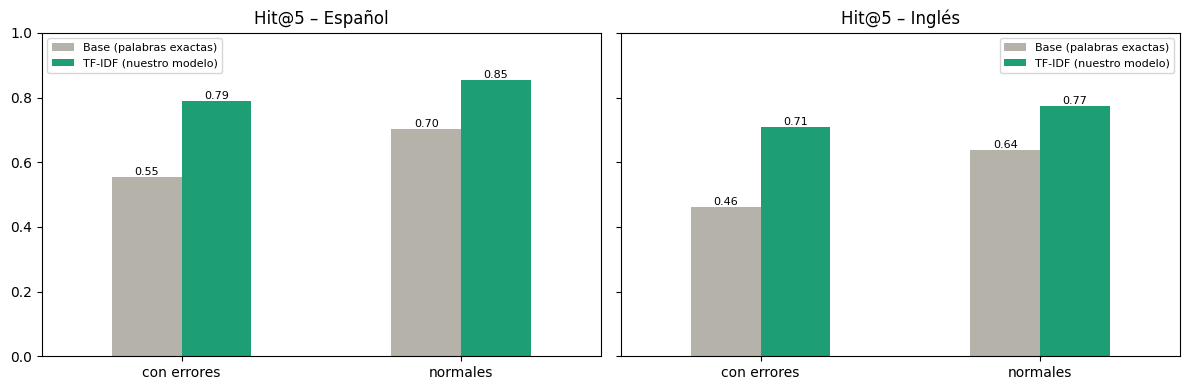

In [20]:
# ============================================================
# PASO 5.5 - GRÁFICO COMPARATIVO (Hit@5)
# ============================================================
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, len(IDIOMAS), figsize=(12, 4), sharey=True)

for ax, idioma in zip(ejes, IDIOMAS):
    datos = df_resultados[df_resultados['idioma'] == idioma]
    # Tabla: filas = tipo de búsqueda, columnas = modelo, valores = Hit@5
    tabla = datos.pivot(index='búsquedas', columns='modelo', values='Hit@5')
    tabla.plot(kind='bar', ax=ax, rot=0, color=['#B4B2A9', '#1D9E75'])
    ax.set_title(f'Hit@5 – {"Español" if idioma == "es" else "Inglés"}')
    ax.set_xlabel('')
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8)
    for barra in ax.patches:                       # muestra el valor sobre cada barra
        ax.annotate(f'{barra.get_height():.2f}',
                    (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                    ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig(f'{RUTA_EXPORT}/grafico_hit5.png', dpi=150)   # se guarda para la presentación
plt.show()

## Paso 6 – Clasificador de categorías con productos reales del ERP
El catálogo de la página todavía es pequeño, así que el modelo no aprende del catálogo sino de
**cómo buscan los clientes**. El dataset de entrenamiento se genera a partir de:
1. Los **481 productos reales del ERP** de Ferreplast (`inventario_valorizado.csv`), convertidos a
   lenguaje de cliente (sin abreviaturas, marcas ni medidas).
2. Un **diccionario de términos** que los clientes usan y el ERP no (chilenismos: cintillo, tiner, huincha aisladora...).
3. **Errores de tipeo** simulados.

⚠ Antes de correr: subir `inventario_valorizado.csv` a la carpeta `datos` del Drive.

In [21]:
import unicodedata
# ============================================================
# PASO 6.0 - CARGAR PRODUCTOS DEL ERP Y ASIGNAR CATEGORÍA
# ============================================================
# El ERP no tiene familias de producto, así que la categoría se asigna
# con reglas de palabras clave. El ORDEN importa: gana la primera regla
# que calce (ej: "PEROXIDO VINILESTER" debe caer en Catalizadores, no en Resinas).
df_erp = pd.read_csv(f'{RUTA_DATOS}/inventario_valorizado.csv', dtype={'sku': str})
df_erp['nombre_limpio'] = df_erp['nombre'].apply(normalizar)

# Filas que no son productos
NO_PRODUCTOS = ['flete', 'muestras comerciales']
df_erp = df_erp[~df_erp['nombre_limpio'].isin(NO_PRODUCTOS)].reset_index(drop=True)

REGLAS = [
    # (expresión regular, categoría)
    (r'\b(molde|piramide)\b',                                         'Moldes y desmoldantes'),
    (r'\b(cera desmoldante|desmoldante)\b',                           'Moldes y desmoldantes'),
    (r'\b(peroxido|cobalto|acelerante|mek|metil etil)\b',             'Catalizadores y aditivos'),
    (r'\b(agente|monomero|talco|carbonato|dioxido de titanio|arena de cuarzo|quita burbuja)\b',
                                                                      'Catalizadores y aditivos'),
    (r'\b(pigmento|pasta)\b',                                         'Pigmentos y pastas'),
    (r'\b(gel coat|gelcoat)\b',                                       'Gel coat'),
    (r'^fv\b|\b(fibra de vidrio|roving)\b',                           'Fibra de vidrio'),
    (r'\b(disco|lija|soporte plato|soporte de goma|grata|cepillo copa)\b', 'Abrasivos y discos'),
    (r'\b(pintura|pntura|esmalte|anticorrosivo|oleo|latex|barniz|zing spray|aceite owb)\b', 'Pinturas y barnices'),
    (r'\b(resina|palatal|vinilester|mdi|polytherm|sistema epoxico|kit epoxico)\b', 'Resinas'),
    (r'\b(diluyente|acetona|aguarras|bencina|alcohoel|alcohol|removedor|acido|soda caustica|desoxidante|decapante)\b',
                                                                      'Diluyentes y solventes'),
    (r'\b(rodillo aireador|zapatilla aireadora)\b',                   'Herramientas'),
    (r'\b(brocha|rodillo|bandeja|multiespatulas|espatula)\b',         'Brochas y rodillos'),
    (r'\b(antiroedores|antiroedor|raticida|insecticida|repelente|veneno|trampa)\b', 'Control de plagas'),
    (r'\b(silicona spray|aflojatuercas|afloja todo|desengrasante|desengripante|limpiador|limpia contacto|shampoo|'
     r'refrigerante|liquido de freno|grasa|bateria|plumilla|aromatizante|aditivo dpf|autoarranque|hidratante|'
     r'revitalizador|protector polos|antideslizante|sellador de parabrisas|proteccion automovil|limpiador de filtro)\b',
                                                                      'Automotriz y mantención'),
    (r'\b(silicona|adhesivo|adesivo|agorex|pega y sella|cola fria|sellador|espuma|no mas clavos|'
     r'soldadura en frio|tapa gotera|pegamento|masilla)\b',          'Adhesivos y selladores'),
    (r'\b(cinta)\b',                                                  'Cintas'),
    (r'\b(guantes?|mascarilla|anteojo|buzo|filtro air|antiderrame)\b',  'Seguridad'),
    (r'\b(broca|alicate|serrucho|martillo|destornillador|huincha|sierra|trincheta|lapiz|pistola)\b', 'Herramientas'),
    (r'\b(clavo|abrazadera)\b',                                       'Fijaciones'),
    (r'\b(balde|bidon|dosificador|vaso dosificador)\b',                'Envases y dosificadores'),
]

def asignar_categoria(nombre):
    for patron, categoria in REGLAS:
        if re.search(patron, nombre):
            return categoria
    return 'Otros'

df_erp['categoria'] = df_erp['nombre_limpio'].apply(asignar_categoria)
print('Productos del ERP:', len(df_erp))
print(df_erp['categoria'].value_counts())
print('\nProductos en "Otros" (revisar a mano):')
print(df_erp.loc[df_erp['categoria'] == 'Otros', 'nombre'].tolist())


Productos del ERP: 481
categoria
Pinturas y barnices         66
Abrasivos y discos          54
Pigmentos y pastas          50
Herramientas                37
Adhesivos y selladores      35
Automotriz y mantención     35
Catalizadores y aditivos    34
Brochas y rodillos          33
Diluyentes y solventes      31
Resinas                     27
Cintas                      15
Seguridad                   14
Fibra de vidrio             13
Gel coat                    12
Moldes y desmoldantes        9
Fijaciones                   7
Envases y dosificadores      5
Otros                        3
Control de plagas            1
Name: count, dtype: int64

Productos en "Otros" (revisar a mano):
['PRESEC - 171 PISO AUTONIVELANTE SACO25 KG', 'TIERRA ROJA QUIMICA UNIVERSAL 1 KG', 'PAÑOS DE LIMPIEZA 1 KG']


In [22]:
# ============================================================
# PASO 6.0b - CONVERTIR NOMBRES DEL ERP EN "COMO BUSCARÍA UN CLIENTE"
# ============================================================
# Los nombres del ERP traen abreviaturas, marcas, códigos y medidas.
# Un cliente escribe "fibra de vidrio mat 450", no "FV MAT 450 EMUL JSH 50 KG".
ABREVIATURAS = {
    'fv': 'fibra de vidrio', 'gno': 'grano', 'gl': 'galon', 'lt': 'litro', 'lts': 'litros',
    'grs': 'gramos', 'gr': 'gramos', 'kg': 'kilo', 'mts': 'metros', 'mt': 'metro',
    'pa': 'preacelerada', 'ug': 'uso general', 'isof': 'isoftalica', 'iso': 'isoftalica',
    'emul': 'emulsion', 'wr': 'woven roving', 'c/': 'con', 'p/': 'para', 's/': 'sin',
    'alcohoel': 'alcohol', 'adesivo': 'adhesivo', 'pntura': 'pintura', 'eco': '',
}
# Marcas y códigos que el cliente casi nunca escribe (se sacan de la versión "corta")
MARCAS = ['passol', 'wurth', 'whurt', 'w max', 'chicauma', 'klingspor', 'fixtec', 'patagon',
          'lizcal', 'liscal', 'pochteca', 'jushi', 'jsh', 'fibratec', 'textron', 'poliya', 'plaquimet',
          'adiplast', 'getpro', 'hoklp', 'coofix', 'old wood brothers', 'owb', 'artp', 'rex', 'fbt',
          'fbtc', 'ftx', 'hsco', 'din338', 'stanley', 'geolite', 'novalax', 'quimetke', 'firecut',
          'alpha pro', 'python', 'yoko', 'merican', 'mn', 'hela', 'maize', 'flatblade', 'rush', 'razor']

def nombre_a_busqueda(nombre):
    t = unicodedata.normalize('NFD', str(nombre).lower())
    t = ''.join(c for c in t if unicodedata.category(c) != 'Mn')     # sin tildes
    t = re.sub(r'\b([cps])/', r'\1/ ', t)                            # c/goma -> c/ goma
    t = re.sub(r'(\d)[.,](\d)', r'\1.\2', t)                          # 8,5 -> 8.5
    t = re.sub(r'[^a-z0-9/.\s]', ' ', t).replace('-', ' ')
    t = ' '.join(ABREVIATURAS.get(p, p) for p in t.split())
    N = r'\d+(?:\.\d+)?'
    t = re.sub(r'\bral \d+', ' ', t)                                             # códigos de color RAL
    t = re.sub(rf'\b{N}\s*x\s*{N}(\s*x\s*{N})?', ' ', t)                       # 115x1.0x22, 230x280
    t = re.sub(r'\b\d+ \d/\d\b|\b\d/\d\b', ' ', t)                              # 4 1/2, 1/4
    t = re.sub(rf'\b{N}\s*(kilo|kilos|litro|litros|gramos|metros|metro|ml|cc|cm|mm|galon)\b', ' ', t)  # 5 kilo
    t = re.sub(rf'\b(galon|kilo|litro|litros|gramos|ml|cc|mm|cm|saco)\b', ' ', t)  # unidades sueltas
    t = re.sub(rf'\b\d+\.\d+\b', ' ', t)                                         # decimales sueltos (3.78)
    for marca in MARCAS:
        t = re.sub(r'\b' + marca + r'\b', ' ', t)
    t = re.sub(r'(?<!\w)[./]+(?!\w)', ' ', t)                                     # puntos o barras sueltas
    return re.sub(r'\s+', ' ', t).strip()

df_erp['busqueda'] = df_erp['nombre'].apply(nombre_a_busqueda)
for _, f in df_erp.sample(15, random_state=SEED).iterrows():
    print(f'{f["nombre"][:50]:50} -> {f["busqueda"]}')


RESINA PA 1 KG                                     -> resina preacelerada
HOJA DE LIJA AL AGUA W-MAX G320                    -> hoja de lija al agua g320
ALICATE UNIVERSAL 7" FIXTEC                        -> alicate universal 7
AGOREX 60 ADHESIVO 120 CC                          -> agorex 60 adhesivo
HOJA DE LIJA AL AGUA W-MAX G240                    -> hoja de lija al agua g240
HOJA LIJA FIERRO MANUAL WURTH GRANO 40 230X280     -> hoja lija fierro manual grano 40
COLA FRIA EXTRA RAPIDA AGOREX 1 KG                 -> cola fria extra rapida agorex
BROCA BLISTER HSCO 8,5 MM                          -> broca blister
RODILLO PATAGON 18 CM 20 MM                        -> rodillo
PIGMENTO PERLANTE FIBRATEC GRIS ACERO 30 GR        -> pigmento perlante gris acero
FV MAT 450 5 KG                                    -> fibra de vidrio mat 450
SILICONA NEUTRA NEGRA POCHTECA 280 ML              -> silicona neutra negra
RODILLO 5072 6 MM 7 CM                             -> rodillo 5072
PINTURA ACRILI

In [23]:
# ============================================================
# PASO 6.1 - GENERAR DATASET DE BÚSQUEDAS (ERP + DICCIONARIO)
# ============================================================
# Dos fuentes:
#  1) Los productos REALES del ERP (versión "como busca un cliente").
#  2) Términos que NO aparecen en el ERP pero los clientes sí escriben
#     (chilenismos y nombres comunes). Ej: "cintillo", "huincha aisladora", "tiner".
TERMINOS_EXTRA = {
    'Resinas':                  ['resina', 'resina poliester', 'resina epoxica', 'resina epoxi', 'resina cristal',
                                 'resina para fibra', 'resina transparente', 'epoxico', 'poliuretano'],
    'Catalizadores y aditivos': ['catalizador', 'catalizador resina', 'endurecedor', 'meck', 'acelerador',
                                 'estireno', 'carga para resina', 'tixotropico', 'cobalto'],
    'Fibra de vidrio':          ['fibra de vidrio', 'fibra', 'mat', 'mat 450', 'roving', 'tela de fibra',
                                 'tela fibra de vidrio', 'velo de superficie'],
    'Gel coat':                 ['gelcoat', 'gel coat', 'gelcoat blanco', 'gelcoat color'],
    'Pigmentos y pastas':       ['pigmento', 'tinte para resina', 'colorante resina', 'pasta de color', 'glitter',
                                 'pigmento perlado', 'mica'],
    'Moldes y desmoldantes':    ['desmoldante', 'cera desmoldante', 'molde de silicona', 'alcohol polivinilico', 'pva'],
    'Pinturas y barnices':      ['pintura', 'esmalte', 'esmalte al agua', 'oleo', 'latex', 'barniz', 'anticorrosivo',
                                 'pintura spray', 'spray', 'pintura epoxica', 'pintura piso'],
    'Diluyentes y solventes':   ['diluyente', 'thinner', 'tiner', 'aguarras', 'acetona', 'solvente', 'parafina'],
    'Brochas y rodillos':       ['brocha', 'pincel', 'rodillo', 'rodillo de pintura', 'bandeja pintura', 'espatula',
                                 'rodillo para fibra'],
    'Abrasivos y discos':       ['lija', 'lija al agua', 'lija para fierro', 'lija para madera', 'disco de corte',
                                 'disco flap', 'disco galletero', 'disco desbaste', 'disco diamantado', 'escobilla'],
    'Adhesivos y selladores':   ['silicona', 'pegamento', 'agorex', 'cola fria', 'sellador', 'la gotita',
                                 'pegamento pvc', 'espuma expansiva', 'masilla', 'pega todo'],
    'Cintas':                   ['cinta', 'huincha aisladora', 'cinta aisladora', 'scotch', 'cinta de embalaje',
                                 'masking tape', 'cinta de papel', 'cinta americana'],
    'Herramientas':             ['huincha', 'huincha de medir', 'martillo', 'alicate', 'serrucho', 'broca',
                                 'destornillador', 'cartonero', 'cuchillo cartonero', 'sierra', 'pistola silicona'],
    'Seguridad':                ['guantes', 'guantes de nitrilo', 'mascarilla', 'antiparras', 'lentes de seguridad',
                                 'buzo desechable', 'respirador'],
    'Automotriz y mantención':  ['lubricante', 'afloja todo', 'grasa', 'refrigerante', 'limpiador de frenos',
                                 'shampoo auto', 'aromatizante auto', 'plumilla', 'bateria auto', 'liquido de frenos'],
    'Fijaciones':               ['clavo', 'clavos', 'abrazadera', 'cintillo', 'amarra plastica'],
    'Envases y dosificadores':  ['balde', 'bidon', 'vaso dosificador', 'envase plastico'],
    'Control de plagas':        ['laucha', 'lauchas', 'guaren', 'guarenes', 'raton', 'ratones', 'rata', 'ratas',
                                 'roedor', 'roedores', 'raticida', 'veneno para ratones', 'veneno para ratas',
                                 'trampa para ratones', 'repelente', 'repelente de roedores', 'antiroedores',
                                 'insecticida', 'cucarachas', 'hormigas', 'polillas', 'chinches', 'zancudos',
                                 'moscas', 'plaga', 'plagas', 'fumigar', 'matar ratones'],
}

PLANTILLAS = ['{t}', '{t}', '{t}', 'comprar {t}', '{t} barato', '{t} precio', 'necesito {t}',
              'busco {t}', '{t} oferta', 'kit {t}', '{t} grande', '{t} chico', '{t} puerto montt']

# Grupos: cada producto del ERP o cada término extra es un "grupo".
# Sirve para evaluar con productos que el modelo NUNCA vio (Paso 6.2).
grupos = []
for _, f in df_erp[df_erp['categoria'] != 'Otros'].iterrows():
    palabras = f['busqueda'].split()
    bases = {f['busqueda'], ' '.join(palabras[:1]), ' '.join(palabras[:2]), ' '.join(palabras[:3])}
    grupos.append({'grupo': f['sku'], 'categoria': f['categoria'], 'bases': sorted(bases), 'origen': 'ERP'})
for categoria, terminos in TERMINOS_EXTRA.items():
    for t in terminos:
        grupos.append({'grupo': 'extra_' + t, 'categoria': categoria, 'bases': [t], 'origen': 'diccionario'})
df_grupos = pd.DataFrame(grupos)

def generar_consultas(df_g, n_por_grupo=20, plantillas=PLANTILLAS, prob_error=0.5, seed=SEED):
    rng = random.Random(seed)
    filas = []
    for _, g in df_g.iterrows():
        # Si el grupo trae su propio "n" (Paso 6.1b), se usa el menor de los dos
        n = n_por_grupo
        if 'n' in g and pd.notna(g['n']):
            n = min(n_por_grupo, int(g['n']))
        for _ in range(n):
            q = rng.choice(plantillas).format(t=rng.choice(g['bases']))
            if rng.random() < prob_error:
                q = agregar_error(q, rng)
            filas.append({'consulta': normalizar(q), 'categoria': g['categoria'], 'grupo': g['grupo']})
    return pd.DataFrame(filas).drop_duplicates(['consulta', 'categoria']).reset_index(drop=True)

df_consultas = generar_consultas(df_grupos)
df_consultas.to_csv(f'{RUTA_DATOS}/consultas_sinteticas.csv', index=False, encoding='utf-8-sig')
print('Grupos (productos ERP + términos):', len(df_grupos), '| Ejemplos generados:', len(df_consultas))
print(df_consultas['categoria'].value_counts())


Grupos (productos ERP + términos): 638 | Ejemplos generados: 9693
categoria
Pinturas y barnices         1127
Abrasivos y discos           924
Pigmentos y pastas           815
Automotriz y mantención      763
Adhesivos y selladores       740
Catalizadores y aditivos     687
Herramientas                 656
Diluyentes y solventes       588
Resinas                      576
Brochas y rodillos           561
Control de plagas            463
Seguridad                    367
Cintas                       364
Fibra de vidrio              304
Moldes y desmoldantes        213
Gel coat                     210
Fijaciones                   185
Envases y dosificadores      150
Name: count, dtype: int64


### Paso 6.1b – Búsquedas en inglés
Se agregan al entrenamiento búsquedas reales de clientes de Amazon (dataset ESCI), en inglés y español, asignadas a las 17 categorías con reglas de palabras clave (*weak labeling*), más un diccionario corto en inglés. Así el modelo aprende términos como "wax", "sandpaper" o "paint thinner".

⚠ Requiere tener cargado `df_examples` (Paso 2.2). Si no está, usa `datos/esci_busquedas.csv`.

In [24]:
# ============================================================
# PASO 6.1b - AGREGAR BÚSQUEDAS EN INGLÉS (ESCI + DICCIONARIO)
# ============================================================
# El modelo del Paso 6.1 solo conoce español. Aquí se le agregan:
#  1) Búsquedas REALES de clientes de Amazon (dataset ESCI del Paso 2), en inglés y
#     español, asignadas a nuestras 17 categorías con reglas de palabras clave
#     ("etiquetado débil" o weak labeling: las reglas ponen la etiqueta, el modelo aprende de ellas).
#  2) Un diccionario corto de términos en inglés que ESCI casi no trae (ej: "car wax").
# Requiere: df_examples (Paso 2.2). Si no está en memoria, usa datos/esci_busquedas.csv.

# ---------- 1) Reglas: frase -> categoría (gana la PRIMERA que calce) ----------
REGLAS_ESCI = [
    # Frases específicas que deben ganarle a reglas más generales
    (r'\b(silicone molds?|resin molds?|epoxy molds?|mold release|molde de silicona|moldes? para resina|desmoldante)\b', 'Moldes y desmoldantes'),
    (r'\b(paint ?brush(es)?|paint rollers?|roller covers?|paint tray|putty knife|scraper|brochas? (de|para) pint\w*|rodillos? (de|para) pint\w*|rodillo|espatula)\b', 'Brochas y rodillos'),
    (r'\b(tape measure|measuring tape|cinta metrica|flexometro|caulking gun|caulk gun|glue gun|pistola (de )?silicona|drill bits?|brocas?)\b', 'Herramientas'),
    (r'\b(electrical tape|duct tape|masking tape|painters? tape|packing tape|teflon tape|thread seal tape|cinta (aislante|americana|de embalar|de carrocero|adhesiva|de pintor|teflon))\b', 'Cintas'),
    (r'\b(work gloves|nitrile gloves|safety (glasses|goggles)|respirator|dust mask|n95|hard hat|ear ?plugs|ear muffs|guantes (de trabajo|de nitrilo)|gafas de proteccion|mascarilla|casco de (obra|seguridad)|tapones (para los )?oidos)\b', 'Seguridad'),
    (r'\b(car wax|turtle wax|paste wax|spray wax|wax polish|car wash|car shampoo|wash and wax|brake fluid|brake cleaner|tire shine|tyre shine|wd ?40|penetrating oil|lubricant|grease|degreaser|car battery|wiper blades?|coolant|antifreeze|car air freshener|leather conditioner|headlight restor\w*|cera (para )?coche|champu (para )?coche|liquido de frenos|lubricante|grasa|desengrasante|limpiaparabrisas|anticongelante|ambientador coche)\b', 'Automotriz y mantención'),
    (r'\b(rat traps?|mouse traps?|rodent repellent|rat poison|mouse poison|pest control|insecticide|bug spray|ant killer|roach|cockroach|raticida|veneno para ratas|trampa para ratones|insecticida|repelente de roedores|cucarachas)\b', 'Control de plagas'),
    (r'\b(hardener|catalyst|mekp|accelerator|cobalt|styrene|endurecedor|catalizador)\b', 'Catalizadores y aditivos'),
    (r'\b(gel ?coat)\b', 'Gel coat'),
    (r'\b(resin pigments?|epoxy pigments?|mica powder|pigment powder|alcohol inks?|resin dye|epoxy dye|pigmentos?|colorante (para )?resina|tinte (para )?resina)\b', 'Pigmentos y pastas'),
    (r'\b(fiberglass (cloth|mat|fabric|repair|resin kit)|chopped strand|woven roving|fiberglass|fibra de vidrio)\b', 'Fibra de vidrio'),
    (r'\b(epoxy resin|casting resin|polyester resin|resin kit|uv resin|deep pour|table top epoxy|resin|resina( epoxi)?)\b', 'Resinas'),
    (r'\b(paint thinner|mineral spirits|acetone|lacquer thinner|turpentine|isopropyl alcohol|solvent|disolvente|diluyente|acetona|aguarras|alcohol isopropilico)\b', 'Diluyentes y solventes'),
    (r'\b(spray paint|wall paint|exterior paint|interior paint|chalk paint|enamel paint|metal paint|wood stain|varnish|polyurethane finish|primer|pintura|esmalte|barniz|imprimacion|laca)\b', 'Pinturas y barnices'),
    (r'\b(sandpaper|sanding (discs?|sheets?|sponge|block)|grinding wheels?|cut(ting)? off wheels?|cutting discs?|flap discs?|wire (brush|wheel|cup)|lija|disco (de corte|de lija|de desbaste|flap)|discos de corte)\b', 'Abrasivos y discos'),
    (r'\b(caulk|silicone sealant|sealant|wood glue|super glue|gorilla glue|construction adhesive|epoxy (glue|adhesive|putty)|wood filler|putty|silicona|pegamento|sellador|masilla|adhesivo|cola blanca|cola de contacto)\b', 'Adhesivos y selladores'),
    (r'\b(wood screws|drywall screws|deck screws|screws|bolts|hex nuts?|lock nuts?|wing nuts?|nuts and bolts|washers|drywall anchors?|wall anchors?|(finishing|framing|brad|concrete) nails|zip ties|cable ties|rivets?|tornillos?|tuercas?|arandelas?|tacos? (de )?(pared|nylon|fischer)|clavos|bridas|remaches?)\b', 'Fijaciones'),
    (r'\b(drill|screwdriver|hammer|pliers|wrench|allen (key|wrench)|hand saw|hacksaw|saw blades?|utility knife|box cutter|laser level|spirit level|angle grinder|orbital sander|sander|multimeter|taladro|destornillador|atornillador|martillo|alicates?|llave (inglesa|allen)|serrucho|sierra|cuter|nivel laser|amoladora|radial|lijadora|multimetro)\b', 'Herramientas'),
    (r'\b(5 gallon bucket|bucket|mixing cups?|measuring cups? (for )?(resin|epoxy)|graduated cups?|cubo|balde|bidon|vaso medidor|vasos medidores)\b', 'Envases y dosificadores'),
]
# Búsquedas que NO son de ferretería aunque contengan una palabra clave
EXCLUIR_ESCI = [
    'nail polish', 'nail art', 'nail drill', 'nail glue', 'press on', 'lash', 'wig', 'hair', 'makeup',
    'cosmetic', 'toys?\\b', 'kids', 'baby', 'dog\\b', 'cats?\\b', 'pets?\\b', 'costume', 'jewelry', 'earring', 'necklace',
    'cake', 'chocolate', 'candy', 'soap molds?', 'bar soap', 'hand soap', 'baking', 'kitchen', 'christmas',
    'halloween', 'iphone', 'samsung', 'phone', 'case\\b', 'guitar', 'bike', 'puzzle', 'lego', 'face paint',
    'body paint', 'paint by number', 'canvas', 'tattoo', 'book', 'figurine', 'statue', 'furniture', 'chair',
    'wicker', 'planter', 'shed', 'pressure washer', 'washing machine', 'lint roller', 'foam roller',
    'makeup brush', 'candle', 'wax melts?', 'wax warmer', 'ear wax', 'waxing', 'bikini',
    'unas', 'pelo', 'maquillaje', 'juguete', 'nino', 'nina', 'bebe', 'perro', 'gato', 'mascota', 'cocina',
    'tarta', 'navidad', 'movil', 'funda', 'libro', 'disfraz', 'figura', 'mueble', 'silla', 'jardin', 'vela',
]
# \b al inicio: "silla" excluye "silla de oficina" pero NO "masilla"
patron_excluir = re.compile(r'\b(?:' + '|'.join(EXCLUIR_ESCI) + r')')
reglas_compiladas = [(re.compile(p), c) for p, c in REGLAS_ESCI]

def categoria_esci(consulta_normalizada):
    if patron_excluir.search(consulta_normalizada):
        return None
    for patron, categoria in reglas_compiladas:
        if patron.search(consulta_normalizada):
            return categoria
    return None

# ---------- 2) Tomar las búsquedas de ESCI ----------
if 'df_examples' in globals():
    fuente = df_examples[['query', 'product_locale']].drop_duplicates()
else:
    print('df_examples no está en memoria: se usa datos/esci_busquedas.csv (menos búsquedas).')
    fuente = pd.read_csv(f'{RUTA_DATOS}/esci_busquedas.csv')[['query', 'product_locale']].drop_duplicates()

fuente = fuente.assign(consulta=fuente['query'].apply(normalizar))
fuente['categoria'] = fuente['consulta'].apply(categoria_esci)
esci_etiquetado = fuente.dropna(subset=['categoria']).drop_duplicates('consulta')

# Balance: máximo por categoría e idioma, para que ninguna categoría domine
MAX_POR_CATEGORIA = 300
esci_etiquetado = (esci_etiquetado.sample(frac=1, random_state=SEED)          # se mezclan al azar
                   .groupby(['categoria', 'product_locale']).head(MAX_POR_CATEGORIA))

print('Búsquedas de ESCI etiquetadas por categoría e idioma:')
print(esci_etiquetado.pivot_table(index='categoria', columns='product_locale',
                                  values='consulta', aggfunc='count', fill_value=0))
print('\nMuestra para revisar a mano:')
print(esci_etiquetado.sample(min(15, len(esci_etiquetado)), random_state=SEED)[['consulta', 'categoria']].to_string(index=False))

# ---------- 3) Diccionario en inglés (términos que ESCI casi no trae) ----------
TERMINOS_INGLES = {
    'Resinas':                  ['resin', 'epoxy resin', 'polyester resin', 'casting resin', 'fiberglass resin', 'clear resin'],
    'Catalizadores y aditivos': ['hardener', 'catalyst', 'mekp', 'resin hardener', 'styrene', 'accelerator'],
    'Fibra de vidrio':          ['fiberglass', 'fiberglass mat', 'fiberglass cloth', 'chopped strand mat', 'woven roving'],
    'Gel coat':                 ['gelcoat', 'gel coat', 'white gelcoat'],
    'Pigmentos y pastas':       ['pigment', 'resin pigment', 'mica powder', 'resin dye', 'color paste'],
    'Moldes y desmoldantes':    ['mold release', 'release wax', 'silicone mold', 'pva release'],
    'Pinturas y barnices':      ['paint', 'spray paint', 'enamel', 'varnish', 'primer', 'wall paint', 'rust paint'],
    'Diluyentes y solventes':   ['thinner', 'paint thinner', 'acetone', 'solvent', 'mineral spirits', 'turpentine'],
    'Brochas y rodillos':       ['paint brush', 'brush', 'paint roller', 'roller', 'paint tray', 'putty knife'],
    'Abrasivos y discos':       ['sandpaper', 'sanding disc', 'cutting disc', 'grinding disc', 'flap disc', 'wire brush'],
    'Adhesivos y selladores':   ['glue', 'sealant', 'silicone', 'caulk', 'adhesive', 'super glue', 'putty'],
    'Cintas':                   ['tape', 'electrical tape', 'duct tape', 'masking tape', 'packing tape'],
    'Herramientas':             ['tape measure', 'hammer', 'pliers', 'screwdriver', 'drill bit', 'saw', 'utility knife'],
    'Seguridad':                ['gloves', 'nitrile gloves', 'safety glasses', 'mask', 'respirator', 'coveralls'],
    'Automotriz y mantención':  ['wax', 'car wax', 'car wash', 'car shampoo', 'brake fluid', 'tire shine',
                                 'glass cleaner', 'leather conditioner', 'lubricant', 'grease', 'coolant', 'air freshener'],
    'Fijaciones':               ['nails', 'screws', 'zip ties', 'cable ties', 'clamp', 'hose clamp'],
    'Envases y dosificadores':  ['bucket', 'mixing cup', 'measuring cup', 'plastic jug'],
    'Control de plagas':        ['rodent', 'rodent repellent', 'rat', 'rats', 'mouse', 'mice', 'rat poison',
                                 'mouse trap', 'pest control', 'insecticide', 'bug spray', 'roach killer'],
}

# ---------- 4) Sumar todo a los grupos del Paso 6.1 y regenerar el dataset ----------
df_grupos['idioma'] = 'es'                      # lo que ya existía (ERP + diccionario español)
nuevos = []
for _, f in esci_etiquetado.iterrows():
    nuevos.append({'grupo': 'esci_' + f['consulta'], 'categoria': f['categoria'], 'bases': [f['consulta']],
                   'origen': 'ESCI', 'idioma': 'en' if f['product_locale'] == 'us' else 'es', 'n': 6})
for categoria, terminos in TERMINOS_INGLES.items():
    for t in terminos:
        nuevos.append({'grupo': 'en_' + t, 'categoria': categoria, 'bases': [t],
                       'origen': 'diccionario_en', 'idioma': 'en', 'n': 20})
df_grupos = pd.concat([df_grupos[~df_grupos['origen'].isin(['ESCI', 'diccionario_en'])], pd.DataFrame(nuevos)],
                      ignore_index=True).drop_duplicates('grupo')

df_consultas = generar_consultas(df_grupos)
df_consultas.to_csv(f'{RUTA_DATOS}/consultas_sinteticas.csv', index=False, encoding='utf-8-sig')
print('\nGrupos por origen:')
print(df_grupos['origen'].value_counts())
print('Total ejemplos de entrenamiento:', len(df_consultas))


Búsquedas de ESCI etiquetadas por categoría e idioma:
product_locale            es   us
categoria                        
Abrasivos y discos         2   12
Adhesivos y selladores    48   35
Automotriz y mantención   15   83
Brochas y rodillos        11   35
Catalizadores y aditivos   1    8
Cintas                     3   18
Control de plagas          0   37
Diluyentes y solventes     2    9
Envases y dosificadores   11   52
Fibra de vidrio            1    7
Fijaciones                29   63
Herramientas              73  288
Moldes y desmoldantes      0   14
Pigmentos y pastas         0    3
Pinturas y barnices       35   45
Resinas                    7   40
Seguridad                 17   81

Muestra para revisar a mano:
                       consulta               categoria
 national geographic sierra map            Herramientas
     14 flute oil filter wrench            Herramientas
                    grease bags Automotriz y mantención
          adhesivo transparente  Adhesivos y s

In [25]:
# ============================================================
# PASO 6.2 - SEPARAR ENTRENAMIENTO Y PRUEBA POR PRODUCTO
# ============================================================
# El 20% de los productos/términos queda FUERA del entrenamiento.
# La prueba usa otras frases y SIEMPRE lleva error de tipeo.
# Así medimos si el modelo entiende productos que nunca vio.
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
idx_tr, idx_te = next(gss.split(df_grupos, groups=df_grupos['grupo']))
grupos_train, grupos_test = df_grupos.iloc[idx_tr], df_grupos.iloc[idx_te]

PLANTILLAS_TEST = ['{t}', 'quiero {t}', '{t} economico', 'donde venden {t}', '{t} stock', 'valor {t}']
train = generar_consultas(grupos_train)
test  = generar_consultas(grupos_test, n_por_grupo=8, plantillas=PLANTILLAS_TEST, prob_error=1.0, seed=7)
print(f'Entrenamiento: {len(train)} ejemplos ({len(grupos_train)} grupos)')
print(f'Prueba:        {len(test)} ejemplos ({len(grupos_test)} grupos nunca vistos)')


Entrenamiento: 14050 ejemplos (1468 grupos)
Prueba:        2486 ejemplos (368 grupos nunca vistos)


In [26]:
# ============================================================
# PASO 6.3 - CLASIFICADOR (TF-IDF + REGRESIÓN LOGÍSTICA) vs BASE
# ============================================================
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
import joblib

def nuevo_clasificador():
    return Pipeline([
        ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5),
                                  sublinear_tf=True, max_features=30000)),
        ('modelo', LogisticRegression(max_iter=3000, C=10)),
    ])

clasificador = nuevo_clasificador().fit(train['consulta'], train['categoria'])
pred = clasificador.predict(test['consulta'])

# Buscador base: busca la palabra EXACTA en los nombres del ERP de entrenamiento
# y devuelve la categoría más común entre los que coinciden.
vocab_base = {}
for _, g in grupos_train.iterrows():
    for b in g['bases']:
        for p in b.split():
            vocab_base.setdefault(p, []).append(g['categoria'])
def categoria_base(q):
    votos = [c for p in q.split() for c in vocab_base.get(p, [])]
    return max(set(votos), key=votos.count) if votos else 'Sin resultado'
pred_base = test['consulta'].apply(categoria_base)

print('Base (palabra exacta)  accuracy:', round(accuracy_score(test['categoria'], pred_base), 3))
print('Nuestro clasificador   accuracy:', round(accuracy_score(test['categoria'], pred), 3))
print('Nuestro clasificador   F1 macro:', round(f1_score(test['categoria'], pred, average='macro'), 3))
print()
print(classification_report(test['categoria'], pred, zero_division=0))

# Resultado por idioma (si se corrió el Paso 6.1b)
if 'idioma' in df_grupos.columns:
    idioma_test = test['grupo'].map(df_grupos.set_index('grupo')['idioma']).fillna('es')
    for idioma, nombre in [('es', 'Español'), ('en', 'Inglés')]:
        m = (idioma_test == idioma).to_numpy()
        if m.sum():
            print(f'{nombre:8} -> base: {accuracy_score(test["categoria"][m], pred_base[m]):.3f} | '
                  f'clasificador: {accuracy_score(test["categoria"][m], pred[m]):.3f}  ({m.sum()} búsquedas)')
    print()

# MODELO FINAL: una vez evaluado, se reentrena con TODOS los datos
clasificador = nuevo_clasificador().fit(df_consultas['consulta'], df_consultas['categoria'])
joblib.dump(clasificador, f'{RUTA_MODELOS}/clasificador_categorias.pkl')
print('Modelo final entrenado con todo y guardado: modelos/clasificador_categorias.pkl')


Base (palabra exacta)  accuracy: 0.675
Nuestro clasificador   accuracy: 0.889
Nuestro clasificador   F1 macro: 0.892

                          precision    recall  f1-score   support

      Abrasivos y discos       0.86      0.95      0.90       100
  Adhesivos y selladores       0.86      0.85      0.86       218
 Automotriz y mantención       0.85      0.87      0.86       235
      Brochas y rodillos       0.94      0.88      0.91       123
Catalizadores y aditivos       0.67      0.91      0.77        99
                  Cintas       1.00      0.95      0.98        66
       Control de plagas       0.82      0.87      0.84        84
  Diluyentes y solventes       0.96      0.65      0.78        72
 Envases y dosificadores       0.94      0.87      0.90        69
         Fibra de vidrio       1.00      1.00      1.00         6
              Fijaciones       0.94      0.80      0.86       132
                Gel coat       1.00      1.00      1.00        30
            Herramienta

In [27]:
# ============================================================
# PASO 6.4 - PROBAR EL CLASIFICADOR
# ============================================================
def predecir_categoria(consulta, top=3):
    probs = clasificador.predict_proba([normalizar(consulta)])[0]
    orden = np.argsort(-probs)[:top]
    return [(clasificador.classes_[i], round(float(probs[i]), 3)) for i in orden]

for q in ['rezina poliester', 'catalisador', 'gelcot blanco', 'fibra de vidrio mat 450',
          'tiner', 'cintillos', 'huincha aisladora', 'lija para fierro', 'pegamento para pvc',
          'guantes nitrilo', 'disco para galletero', 'tinte para resina']:
    print(f'{q:25} -> {predecir_categoria(q)}')


rezina poliester          -> [('Resinas', 0.877), ('Pigmentos y pastas', 0.087), ('Herramientas', 0.006)]
catalisador               -> [('Catalizadores y aditivos', 0.908), ('Herramientas', 0.033), ('Automotriz y mantención', 0.025)]
gelcot blanco             -> [('Gel coat', 0.967), ('Pinturas y barnices', 0.007), ('Envases y dosificadores', 0.004)]
fibra de vidrio mat 450   -> [('Fibra de vidrio', 1.0), ('Seguridad', 0.0), ('Brochas y rodillos', 0.0)]
tiner                     -> [('Diluyentes y solventes', 0.993), ('Automotriz y mantención', 0.002), ('Herramientas', 0.001)]
cintillos                 -> [('Fijaciones', 0.999), ('Cintas', 0.0), ('Herramientas', 0.0)]
huincha aisladora         -> [('Cintas', 0.944), ('Herramientas', 0.053), ('Adhesivos y selladores', 0.001)]
lija para fierro          -> [('Abrasivos y discos', 0.972), ('Herramientas', 0.016), ('Pinturas y barnices', 0.003)]
pegamento para pvc        -> [('Adhesivos y selladores', 0.999), ('Pigmentos y pastas', 0.001), 

In [28]:
# ============================================================
# PASO 6.5 - BUSCADOR HÍBRIDO SOBRE EL CATÁLOGO
# ============================================================
# Puntaje final = 60% parecido del texto + 40% probabilidad de la categoría.
# Se usa el catálogo del ERP (lo que la página tendrá a futuro).
# Para buscar solo en los productos que HOY están en la página, filtrar
# catalogo por los sku publicados.
catalogo = df_erp.copy()

# ETIQUETAS: palabras que el cliente usa pero que NO están en el nombre del ERP.
# Ej: nadie busca "peroxido mek", buscan "catalizador". Se agregan al texto del producto.
ETIQUETAS = {
    'peroxido':            'catalizador',
    'cobalto':             'acelerador',
    'acelerante':          'acelerador',
    'abrazadera':          'cintillo amarra plastica',
    'diluyente':           'thinner tiner',
    'trincheta':           'cartonero cuchillo cartonero',
    'cinta aisladora':     'huincha aisladora',
    'cinta de enmascarar': 'masking tape',
    'anteojo':             'antiparras lentes de seguridad',
    'desmoldante pva':     'alcohol polivinilico',
    'gel coat':            'gelcoat',
    'fv ':                 'fibra de vidrio',
}
def etiquetas(nombre):
    return ' '.join(v for k, v in ETIQUETAS.items() if k in nombre + ' ')

catalogo['texto'] = (catalogo['nombre_limpio'] + ' ' + catalogo['busqueda'] + ' '
                     + catalogo['nombre_limpio'].apply(etiquetas))      # nombre ERP + versión cliente + etiquetas

vec_cat = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), sublinear_tf=True)
X_cat = vec_cat.fit_transform(catalogo['texto'])

def buscar_ferreplast(consulta, top=5, peso_texto=0.6, peso_cat=0.4, minimo=0.15):
    q = normalizar(consulta)
    sim = (X_cat @ vec_cat.transform([q]).T).toarray().ravel()                 # parecido de texto
    probs = dict(zip(clasificador.classes_, clasificador.predict_proba([q])[0]))
    p_cat = catalogo['categoria'].map(probs).fillna(0).to_numpy()              # prob. de su categoría
    puntaje = peso_texto * sim + peso_cat * p_cat
    orden = [i for i in np.argsort(-puntaje)[:top] if puntaje[i] >= minimo]   # descarta resultados débiles
    res = catalogo.iloc[orden][['sku', 'nombre', 'categoria']].copy()
    res['puntaje'] = puntaje[orden].round(3)
    return res.reset_index(drop=True)

for q in ['rezina poliester', 'catalisador', 'gelcot blanco', 'huincha', 'tiner',
          'disco para galletero', 'cintillos', 'lija para fierro']:
    print(f'\n🔎 "{q}"   categoría: {predecir_categoria(q, 1)[0]}')
    print(buscar_ferreplast(q, 3)[['nombre', 'puntaje']].to_string(index=False))



🔎 "rezina poliester"   categoría: ('Resinas', 0.877)
                                             nombre  puntaje
            RESINA POLIESTER USO GENERAL IMP. 20 KG    0.680
   RESINA POLIESTER INSATURADO TEXTRON ECO PA 60 KG    0.633
RESINA POLIESTER USO GENERAL ORTOFTALICA 196 220 KG    0.614

🔎 "catalisador"   categoría: ('Catalizadores y aditivos', 0.908)
              nombre  puntaje
   PEROXIDO MEK 5 KG    0.544
 PEROXIDO MEK 20 GRS    0.541
PEROXIDO MEK 100 Grs    0.539

🔎 "gelcot blanco"   categoría: ('Gel coat', 0.967)
                        nombre  puntaje
   GEL COAT ISO PA BLANCO 5 KG    0.669
  GEL COAT ISO PA BLANCO 20 KG    0.667
GEL COAT BLANCO ISOF PA 220 KG    0.657

🔎 "huincha"   categoría: ('Herramientas', 0.99)
                              nombre  puntaje
       HUINCHA DE MEDIR 5 MTS FIXTEC    0.780
huincha de medir c/goma 10 mts 25 mm    0.733
      TRINCHETA UNIVERSAL 18MM W-MAX    0.435

🔎 "tiner"   categoría: ('Diluyentes y solventes', 0.993)
             

## Paso 7 – Exportar el modelo para la página
Se exporta el clasificador a JSON para que la Edge Function de Supabase lo use en TypeScript, y se asigna la categoría del modelo a los productos de la página.

In [29]:
import os, json
# ============================================================
# PASO 7.1 - EXPORTAR EL MODELO PARA LA PÁGINA (JSON)
# ============================================================
# Supabase no ejecuta Python, así que el modelo se exporta como números:
#   vocabulario (fragmento -> columna), pesos IDF, coeficientes y sesgos.
# La Edge Function hace en TypeScript exactamente el mismo cálculo.
#
# Se usan 5.000 fragmentos (en vez de 30.000): la precisión es la misma
# y el archivo baja de ~4 MB a ~0,9 MB.

def clasificador_liviano():
    return Pipeline([
        ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5),
                                  sublinear_tf=True, max_features=5000)),
        ('modelo', LogisticRegression(max_iter=3000, C=10)),
    ])

# Comprobamos con la misma prueba del Paso 6.2 que no se pierde precisión
prueba = clasificador_liviano().fit(train['consulta'], train['categoria'])
print('Accuracy con 5.000 fragmentos:', round(accuracy_score(test['categoria'], prueba.predict(test['consulta'])), 3))

# Modelo final con todos los datos
clasificador_web = clasificador_liviano().fit(df_consultas['consulta'], df_consultas['categoria'])
tfidf  = clasificador_web.named_steps['tfidf']
modelo = clasificador_web.named_steps['modelo']

export = {
    'version':   1,
    'ngram':     list(tfidf.ngram_range),
    'vocab':     {k: int(v) for k, v in tfidf.vocabulary_.items()},
    'idf':       np.round(tfidf.idf_, 6).tolist(),
    'coef':      np.round(modelo.coef_, 6).tolist(),
    'intercept': np.round(modelo.intercept_, 6).tolist(),
    'clases':    modelo.classes_.tolist(),
}
ruta_json = f'{RUTA_EXPORT}/modelo_busqueda.json'
with open(ruta_json, 'w', encoding='utf-8') as f:
    json.dump(export, f, ensure_ascii=False, separators=(',', ':'))
print('Guardado:', ruta_json, f'({os.path.getsize(ruta_json)/1e6:.2f} MB)')

# Casos de prueba: la Edge Function debe dar las MISMAS probabilidades
CONSULTAS_PRUEBA = ['rezina poliester', 'catalisador', 'gelcot blanco', 'fibra de vidrio mat 450',
                    'tiner', 'cintillos', 'huincha aisladora', 'lija para fierro', 'pegamento para pvc',
                    'guantes nitrilo', 'disco para galletero', 'tinte para resina', 'Resina Poliéster 20 KG',
                    'acetona', 'brocha 2"', 'cera desmoldante', 'esmalte al agua blanco', 'broca 8mm',
                    'silicona', 'huincha de medir',
                    'car wax', 'wax', 'sandpaper', 'wood glue', 'paint thinner', 'epoxy resin', 'work gloves']
casos = []
for q in CONSULTAS_PRUEBA:
    probs = clasificador_web.predict_proba([normalizar(q)])[0]
    casos.append({'consulta': q, 'normalizada': normalizar(q),
                  'probs': dict(zip(clasificador_web.classes_, np.round(probs, 6).tolist()))})
with open(f'{RUTA_EXPORT}/casos_prueba.json', 'w', encoding='utf-8') as f:
    json.dump(casos, f, ensure_ascii=False, indent=1)
print('Guardado: export/casos_prueba.json')


Accuracy con 5.000 fragmentos: 0.874
Guardado: /content/drive/MyDrive/busqueda inteligente/export/modelo_busqueda.json (0.98 MB)
Guardado: export/casos_prueba.json


In [ ]:
# ============================================================
# PASO 7.2 - CATEGORÍA DE LOS PRODUCTOS DE LA PÁGINA
# ============================================================
# Cada producto de la página necesita su "categoria_ml" (una de las 17 del modelo).
# 1) En Supabase: Table Editor -> producto -> Export -> CSV.
#    Guardarlo en Drive como datos/productos_pagina.csv
# 2) Esta celda le pone categoría con el MISMO modelo (clasifica el nombre)
#    y genera un archivo SQL para pegar en el SQL Editor de Supabase.
#    Revisen el SQL antes de ejecutarlo: si alguna categoría quedó mal, la corrigen ahí.
df_pag = pd.read_csv(f'{RUTA_DATOS}/productos_pagina.csv')
df_pag['categoria_ml']  = clasificador_web.predict(df_pag['nom_prod'].apply(normalizar))
df_pag['etiquetas_ml']  = df_pag['nom_prod'].apply(lambda n: etiquetas(normalizar(n)))   # función del Paso 6.5
print(df_pag[['id_prod', 'nom_prod', 'categoria_ml', 'etiquetas_ml']].to_string(index=False))

def sql_texto(s):
    return "'" + str(s).replace("'", "''") + "'"

lineas = ['-- Generado en Colab (Paso 7.2). Revisar antes de ejecutar.']
for _, f in df_pag.iterrows():
    lineas.append(f"update producto set categoria_ml = {sql_texto(f['categoria_ml'])}, "
                  f"etiquetas_ml = {sql_texto(f['etiquetas_ml'])} where id_prod = {int(f['id_prod'])};")
with open(f'{RUTA_EXPORT}/actualizar_categorias.sql', 'w', encoding='utf-8') as f:
    f.write('\n'.join(lineas) + '\n')
print('\nGuardado: export/actualizar_categorias.sql')


##FINAL

In [ ]:
# ============================================================
# BUSCADOR INTERACTIVO (para probar y para la demo)
# ============================================================
# ipywidgets crea controles visuales (cuadros de texto, botones)
# dentro del notebook. Colab ya lo trae instalado.
import ipywidgets as widgets
from IPython.display import display, clear_output

# Cuadro de texto donde se escribe la búsqueda
caja = widgets.Text(placeholder='Escribe tu búsqueda y presiona Enter...',
                    layout=widgets.Layout(width='60%'))

# Selector de idioma
idioma_sel = widgets.Dropdown(options=[('Español', 'es'), ('Inglés', 'us')],
                              value='es', description='Idioma:')

salida = widgets.Output()   # zona donde aparecen los resultados

def al_buscar(_):
    """Se ejecuta cada vez que se presiona Enter en el cuadro de texto."""
    with salida:
        clear_output()                                   # borra los resultados anteriores
        consulta = caja.value.strip()
        if not consulta:
            print('Escribe algo para buscar')
            return
        print(f'🔎 "{consulta}"  ->  texto procesado: "{preparar_busqueda(consulta)}"\n')
        res = buscar(consulta, idioma_sel.value, top=10)
        for i, fila in res.iterrows():
            print(f'{i+1:2}. [{fila["puntaje"]:.3f}]  {fila["product_title"][:90]}')

caja.on_submit(al_buscar)      # conecta la tecla Enter con la función
display(widgets.HBox([caja, idioma_sel]), salida)

In [ ]:
# ============================================================
# DIAGNÓSTICO - BÚSQUEDAS Y PRODUCTOS DE RESINA EN ESCI
# ============================================================
# Revisamos el dataset COMPLETO (antes del filtro de ferretería)
# para ver cuánto material de resina existe en cada idioma.

PALABRAS_RESINA = {
    'es': r'\b(?:resina|epoxi|epoxy|endurecedor|gelcoat|fibra de vidrio|poliester)',
    'us': r'\b(?:resin|epoxy|hardener|gelcoat|fiberglass|polyester resin)',
}

for idioma in IDIOMAS:
    # Búsquedas únicas del idioma, normalizadas (sin tildes ni mayúsculas)
    qs = pd.Series(df_examples.loc[df_examples['product_locale'] == idioma, 'query'].unique())
    mask = qs.apply(quitar_tildes).str.contains(PALABRAS_RESINA[idioma], regex=True)

    # Productos del idioma cuyo título menciona resina
    titulos = df_products.loc[df_products['product_locale'] == idioma, 'product_title']
    n_prod = titulos.fillna('').apply(quitar_tildes).str.contains(PALABRAS_RESINA[idioma], regex=True).sum()

    print(f'\n[{idioma}] búsquedas de resina: {mask.sum()} | productos con resina en el título: {n_prod}')
    for q in qs[mask].sample(min(15, mask.sum()), random_state=SEED):
        print('    -', q)